# 07. Кукуруза: понятная версия анализа по годам и режимам — v2

**Главный вопрос:** насколько точно маркеры предсказывают урожайность GY и высоту PH, и что меняется при переносе на другой режим или год?
Ниже видны исходные данные, выбор train/test, вызовы `fit`/`predict`, метрики и графики. Внешнего runner анализа нет.

**«Локальные линии» — не местные сорта.** В опыте E это линии **целевой когорты 2020**, фенотипы которых разрешено добавить в обучение:
из 486 линий 73 идут в обучающий резерв, 413 остаются в test. Для источника 2017–2019: 3041 историческая линия + 73 локальные = 3114 обучающих линий.
Фенотипы 413 test-линий не входят в обучение ни в одном варианте.

**Что изменено в v2:** карта T01–T11; объяснения терминов, годов и режимов; все четыре метрики на панелях A и 2020 B/D;
исправленный BV scatter с r; фактическая IBS train–test; численное сопоставление со статьёй; конкретные выводы после блоков.

**Происхождение outputs.** Обучение и его outputs сохранены из завершённого прогона `20261026T053004Z_4b1b13e7`
(6412 основных оценок, 2 920 292 строк прогнозов). В этой редакции заново выполнены только 16 новых/изменённых ячеек постобработки.
Второй полный обучающий прогон не запускался. Исходные CSV, десять модулей моделей и файлы прогнозов сохранены без изменений.
При вашем **Run All** старые результаты не подставляются вместо обучения: создаётся новый RUN_ID, все модели обучаются с нуля, затем выполняются поясняющие ячейки.

**Честный итог покрытия:** сделан большой набор сравнений, но «всё без оговорок» — неверно.
Не все пять методов испытаны во всех сценариях; C и fixed-F не являются десятью переобучениями; E — только GY Optimal;
GSSI/KSSI не реализованы; два скаляра BRR не прошли порог ESS. Детали — в карте ниже.

## Карта требований T01–T11

Повторяющаяся нумерация исходного задания разведена на 11 смысловых пунктов.
Ниже — краткие формулировки и честные границы покрытия. **Номера — позиции ячеек, начиная с 1, не In[].**
Ссылка пункта ведёт к его основному разделу; номера также включают связанные пояснения, расчёты и проверки.

| Пункт | Краткая формулировка | Статус | Граница / что не следует утверждать | Ячейки |
|---|---|---|---|---|
| [T01](#tz-T01) | Распределения GY/PH по годам и режимам | Выполнено | Средние, разброс, хвосты, единицы; экстремумы test сохранены | 7–10, 75 |
| [T02](#tz-T02) | Методы: r, RMSE, MAE, предиктивный R² | Выполнено в A | Пять методов + baseline, оба признака; не все методы во всех переносах | 15–32, 34, 64–75 |
| [T03](#tz-T03) | Свой / другой / объединённые режимы | Выполнено для трёх моделей | B/D: GBLUP, KBLUP, baseline; не лес/BRR/BayesA | 35–44, 75 |
| [T04](#tz-T04) | PCA, IBS, генетические расстояния по годам | Выполнено | Описательная структура; нет семейных меток и причинного разделения эффектов | 11–14, 75 |
| [T05](#tz-T05) | Влияние близости train/test | Выполнено в F; дополнено E | Фактическая IBS, фиксированный размер; target=2020, не причинная оценка | 14, 45–49, 52–57, 73–75 |
| [T06](#tz-T06) | Нелинейные модели | Выполнено в A | KBLUP и лес; не полный перебор нелинейных моделей/настроек | 15, 22–32, 75 |
| [T07](#tz-T07) | Смысл режимов и годов | Выполнено с ограничениями данных | BLUE тесткроссов; год смешан с когортой и условиями | 3, 6, 10, 40–44, 75 |
| [T08](#tz-T08) | Методы/выводы статьи и наши результаты | Выполнен разбор, не полная репликация | Table 2 GBLUP сопоставлена с E; GSSI/KSSI не реализованы | 45–51, 75 |
| [T09](#tz-T09) | BV–yield scatter, OLS и корреляция | Выполнено | GBLUP, 2020, split 1; x=observed, y=genetic component; аналог PH | 33–34, 75 |
| [T10](#tz-T10) | Одинаковые разбиения, оба признака, повторы | Выполнено внутри постановок; не в полной трактовке | C/fixed-F — target-resampling, не 10 refit; E только GY Optimal | 3, 6, 15–31, 35–48, 52–56, 58–61, 64–76 |
| [T11](#tz-T11) | Фильтры близости, размера и прочие | Выполнено в F/G | Target=2020; train-only, неизменный test; фильтры не всегда полезны | 52–63, 75 |


**Не закрыто, если требовать буквально:** все пять методов во всех сценариях, десять изменяемых train в C/fixed-F,
GSSI/KSSI и локальный опыт E для всех признаков/режимов. В этой редакции новые тяжёлые обучения не выполнялись.


<a id="tz-T07"></a>
## Как устроены данные: годы, режимы и словарь — T07

**Что является объектом.** GID — идентификатор DH-линии (удвоенного гаплоида), не ген.
Генотипировали родительские линии, а в поле оценивали их тесткросс-гибриды. Фенотипы CSV — скорректированные оценки **BLUE**,
а не измерения отдельных растений. GY — урожайность в т/га при влажности 12,5%; PH — высота в см до воротничка флагового листа. [1](https://www.nature.com/articles/s41437-021-00474-1)

| Режим | Что делали в исходном опыте | Что доступно нам |
|---|---|---|
| Optimal | Две обеспеченные водой площадки; сезон дождей и дополнительный полив | Уже скорректированный признак по режиму, не отдельные полевые записи |
| Drought | Одна площадка управляемого стресса в сухой сезон; полив прекращали за две недели до цветения и до уборки | Уже скорректированный признак при дефиците воды |

На каждой площадке было две полевые повторности. Они **не равны** десяти вычислительным разбиениям.
Отдельных идентификаторов площадок, делянок и повторностей в используемых CSV нет; заново восстановить полевую модель из них нельзя.
Место производства DH-линий не следует автоматически считать местом всех испытаний. [1](https://www.nature.com/articles/s41437-021-00474-1)

**Что означает год.** Когорты разные: 2017 — 901 линия, 2018 — 1419, 2019 — 722, 2020 — 486.
Одни и те же гибриды между годами не повторялись, поэтому сдвиг среднего нельзя назвать только «эффектом погоды»:
одновременно меняются генетическая когорта и условия испытаний. Работа описывает 54 двуродительские семьи и общих родителей,
но семейных меток в CSV нет — строгую family-wise CV здесь не провели. [1](https://www.nature.com/articles/s41437-021-00474-1)

Используем 3528 валидных GID опубликованного набора, хотя статья сообщает 3527 итоговых линий.
Нет основания удалять дополнительную строку только для совпадения числа.
4612 маркеров — бинарные доминантные rAmpSeq presence/absence, **не** диплоидные дозировки SNP;
«редкая частота» ниже — частота более редкого бинарного состояния. Данные: [Dryad, 10.5061/dryad.qjq2bvqgz](https://doi.org/10.5061/dryad.qjq2bvqgz). [1](https://www.nature.com/articles/s41437-021-00474-1)

**Словарь для чтения кода**
- **train** — строки с разрешёнными фенотипами для обучения; **test/target** — линии, по которым оценивают прогноз.
- **Признак / trait:** GY или PH; **режим / condition:** Optimal или Drought.
- **fit** оценивает параметры на train; **predict** получает прогноз для test без его фенотипов.
- **Генетическая компонента/BV** ниже — модельная оценка, не измеренная истинная племенная ценность.
- **IBS** в этом ноутбуке — доля совпадающих бинарных маркерных состояний; это сходство, а не доказанная родословная.
- **SD** — разброс результатов повторов соответствующего опыта; не автоматически доверительный интервал и не полевая ошибка.

В следующих ячейках проверяются GID, пропуски и бинарность маркеров. Пропуски фенотипа исключаются только из соответствующего признака/режима;
экстремальные test-значения не удаляются ради улучшения метрик.

In [105]:
# Общий код
from pathlib import Path
from collections import OrderedDict
from itertools import product, permutations
import hashlib, json, time, uuid, sys, platform
from datetime import datetime, timezone
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown
from scipy.linalg import qr
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from threadpoolctl import threadpool_limits
import arviz as az

# Works when launched from the project root or its notebooks/ directory.
ROOT = next((p for p in [Path.cwd(), Path.cwd().parent] if (p/'gp_models').is_dir() and (p/'data/Geno_data.csv').is_file()), None)
if ROOT is None:
    raise FileNotFoundError('Откройте ноутбук из корня проекта или папки notebooks/. Нужны data/ и gp_models/.')
sys.path.insert(0, str(ROOT))
from gp_models.gblup import prepare_gblup, gblup_fit_reml, gblup_predict
from gp_models.kblup import prepare_kblup, kblup_fit, kblup_predict
from gp_models.rrblup import rrblup_fit, predict_gebv
from gp_models.brr import brr_fit
from gp_models.bayesa import bayesa_fit
from gp_models.random_forest import random_forest_fit, random_forest_predict
from gp_models.cv import random_splits, regression_metrics, topk_overlap

CONFIG = dict(repeats=10, train_fraction=.7, seeds=list(range(1,11)),
              gibbs=dict(n_iter=8000,burn_in=2000,thin=5,R2=.5,dfb=4.,dfe=4.,prior_calibration='marker_variance'),
              forest=dict(n_estimators=200,min_samples_leaf=5,max_features=.3,n_jobs=2),
              reml_log_lambda_bounds=[-12.,12.], target_fraction=.85)
# No resume mode is enabled: every Run All creates a new run and fits from scratch.
RUN_ID = datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%SZ')+'_'+uuid.uuid4().hex[:8]
OUT = ROOT/'results'/RUN_ID
OUT.mkdir(parents=True, exist_ok=False)
(OUT/'figures').mkdir()
thread_limit = threadpool_limits(limits=2)
plt.rcParams.update({'font.family':['Liberation Sans','Arimo','DejaVu Sans'], 'svg.fonttype':'none', 'figure.dpi':110})
sns.set_theme(style='ticks', palette='colorblind', font='Liberation Sans')
YEARS, TRAITS, CONDITIONS = [2017,2018,2019,2020], ['GY','PH'], ['Optimal','Drought']
MODELS = ['GBLUP','KBLUP','BRR','BayesA','Random forest','Baseline']
KERNEL_MODELS = ['GBLUP','KBLUP','Baseline']
run_clock = time.perf_counter()
active_seconds = 0.
metrics_rows, prediction_parts, manifest_parts, stage_times = [], [], [], []
trace_store, paired_sets = {}, {}

def sha256(path):
    return hashlib.sha256(Path(path).read_bytes()).hexdigest()

code_hashes = {p.name:sha256(p) for p in sorted((ROOT/'gp_models').glob('*.py'))}
input_hashes = {p.name:sha256(p) for p in sorted((ROOT/'data').glob('*_data.csv'))}
(OUT/'run_config.json').write_text(json.dumps(dict(run_id=RUN_ID,config=CONFIG,code_sha256=code_hashes,input_sha256=input_hashes,python=platform.python_version()),indent=2))
print('Новый запуск:',RUN_ID,'; повторов:',CONFIG['repeats'])

Новый запуск: 20261026T053004Z_4b1b13e7 ; повторов: 10


In [149]:
# maize07_explained_v2: display_helpers
# Общие функции оформления: сохраняют только новые сводки/рисунки, не обучают модели.
from IPython.display import Image, Markdown
from scipy import stats

def show_explained_figure(fig, stem):
    fig.tight_layout()
    for extension in ['png','svg']:
        fig.savefig(OUT/f'figures/{stem}.{extension}',bbox_inches='tight')
    display(Image(filename=str(OUT/f'figures/{stem}.png')))
    plt.close(fig)

def explain_result(title, paragraphs):
    display(Markdown('### '+title+'\n\n'+'\n\n'.join(paragraphs)))

metric_names={'r':'Pearson r','rmse':'RMSE','mae':'MAE','r2':'Предиктивный R²'}

In [106]:
# T07/T10
t0 = time.perf_counter()
pheno = pd.read_csv(ROOT/'data/Pheno_data.csv')
geno = pd.read_csv(ROOT/'data/Geno_data.csv').set_index('GID')
required = ['GID','Year']+[f'{t}_{c}' for t in TRAITS for c in CONDITIONS]
assert set(required).issubset(pheno.columns)
assert pheno.GID.is_unique and geno.index.is_unique
assert set(pheno.GID) == set(geno.index)
assert sorted(pheno.Year.unique()) == YEARS
geno = geno.loc[pheno.GID]
X = geno.to_numpy(dtype=np.float64)
assert np.isfinite(X).all() and np.isin(X,[0.,1.]).all()
assert not geno.duplicated().any(), 'Обнаружены одинаковые профили: требуется отдельная проверка.'
assert not pheno.duplicated().any()
assert np.all(X.var(axis=0)>0)
pheno = pheno.reset_index(drop=True)
pheno['row'] = np.arange(len(pheno))
qc = pheno.groupby('Year').agg(lines=('GID','size'))
for trait, condition in product(TRAITS,CONDITIONS):
    qc[f'{trait}_{condition}'] = pheno.groupby('Year')[f'{trait}_{condition}'].count()
missing = pheno.loc[pheno[[f'{t}_{c}' for t,c in product(TRAITS,CONDITIONS)]].isna().any(axis=1), required]
qc.to_csv(OUT/'input_qc.csv')
missing.to_csv(OUT/'missing_phenotypes.csv',index=False)
display(qc)
display(missing)
print(f'Маркеры: {X.shape[0]} линий × {X.shape[1]} бинарных столбцов; пропусков маркеров: {np.isnan(X).sum()}.')
print('CSV содержат',len(pheno),'строк; нет оснований удалять дополнительную валидную строку ради числа из статьи.')
active_seconds += time.perf_counter()-t0

,lines,GY_Optimal,GY_Drought,PH_Optimal,PH_Drought
Year,,,,,
2017,901,901,901,901,901
2018,1419,1418,1418,1418,1418
2019,722,722,721,722,721
2020,486,486,486,486,486


,GID,Year,GY_Optimal,GY_Drought,PH_Optimal,PH_Drought
1541,973680,2018,NaN,1.1567,NaN,172.66
1953,976304,2018,8.3404,NaN,241.66,NaN
2820,1132699,2019,7.0629,NaN,247.37,NaN


Маркеры: 3528 линий × 4612 бинарных столбцов; пропусков маркеров: 0.
CSV содержат 3528 строк; нет оснований удалять дополнительную валидную строку ради числа из статьи.


<a id="tz-T01"></a>
## 1. Какие группы сравниваем

Распределения помогают увидеть масштабы признаков, сдвиги средних между годами и редкие крайние значения. **Они не используются для удаления test-наблюдений.** В разных годах разные GID: перенос года одновременно проверяет перенос на другую когорту и другие условия. Семейные метки в CSV отсутствуют, поэтому это не проверка переноса на полностью независимые семьи.

In [107]:
# T01
t0 = time.perf_counter()
long_pheno = pheno.melt(id_vars=['GID','Year','row'],value_vars=[f'{t}_{c}' for t,c in product(TRAITS,CONDITIONS)],var_name='variable',value_name='y').dropna(subset=['y'])
long_pheno[['trait','condition']] = long_pheno.variable.str.split('_',expand=True)
phenotype_summary = long_pheno.groupby(['trait','condition','Year']).y.agg(['count','mean','std','median','min','max'])
display(phenotype_summary.round(3))
phenotype_summary.to_csv(OUT/'phenotype_summary.csv')
fig, axes = plt.subplots(2,2,figsize=(11,7))
for ax,(trait,condition) in zip(axes.flat,product(TRAITS,CONDITIONS)):
    data = long_pheno.query('trait == @trait and condition == @condition')
    sns.histplot(data=data,x='y',hue='Year',palette='colorblind',element='step',fill=False,common_norm=False,bins=30,ax=ax)
    ax.set(title=f'{trait} · {condition}',xlabel='Урожайность, т/га' if trait=='GY' else 'Высота, см',ylabel='Число линий')
fig.tight_layout()
fig.savefig(OUT/'figures/phenotypes.png',bbox_inches='tight')
fig.savefig(OUT/'figures/phenotypes.svg',bbox_inches='tight')
plt.show()
active_seconds += time.perf_counter()-t0

count     mean     std   median      min      max
trait condition Year                                                   
GY    Drought   2017    901    3.211   0.824    3.227    1.081    5.298
                2018   1418    3.111   0.768    3.043    0.933    6.353
                2019    721    2.325   0.961    2.295    0.068    5.476
                2020    486    2.259   0.917    2.224    0.311    5.031
      Optimal   2017    901    6.024   0.839    5.986    3.490    9.136
                2018   1418    8.035   1.273    8.113    3.560   11.698
                2019    722    6.370   1.010    6.395    3.513    9.350
                2020    486    7.582   1.678    7.421    4.058   18.836
PH    Drought   2017    901  207.105  14.830  207.730  163.530  244.650
                2018   1418  212.538  15.487  213.415  166.810  264.390
                2019    721  214.493  16.500  214.770  165.820  264.180
                2020    486  200.190  19.701  198.550  153.400  261.100
      Optimal   2017    901  235.318  10.901  234.780  194.330  270.040
                2018   1418  252.832  18.933  253.510  193.630  307.570
                2019    722  247.065  12.137  247.290  209.410  283.850
                2020    486  228.035  12.529  228.600  199.200  267.800

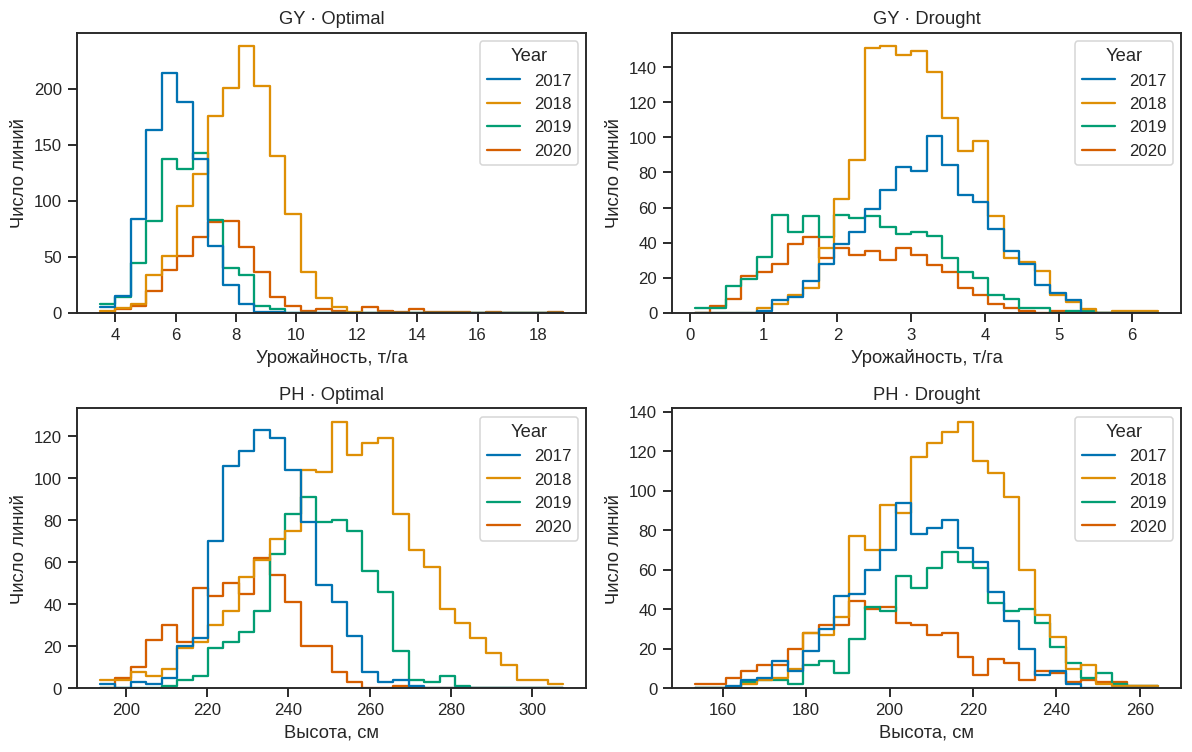

In [137]:
# T01
from IPython.display import Image
display(Image(filename=str(OUT/'figures/phenotypes.png')))

In [150]:
# maize07_explained_v2: distributions_interpretation
# T01: читаем различия признаков, не выдавая их за причинный эффект года/засухи.
rows=phenotype_summary.reset_index()
gy=rows.query("trait == 'GY'").pivot(index='Year',columns='condition',values='mean')
ph=rows.query("trait == 'PH'").pivot(index='Year',columns='condition',values='mean')
means=pd.DataFrame({'GY Optimal, т/га':gy.Optimal,'GY Drought, т/га':gy.Drought,'PH Optimal, см':ph.Optimal,'PH Drought, см':ph.Drought})
display(means.round(2))
explain_result('Что показывают распределения — T01',[
    f"В наших данных средняя GY Optimal меняется от {gy.Optimal.min():.2f} до {gy.Optimal.max():.2f} т/га, а GY Drought — от {gy.Drought.min():.2f} до {gy.Drought.max():.2f} т/га. В каждом году средняя урожайность при Drought ниже, но это сравнение режимов/площадок, не чистая оценка причинного эффекта отключения воды.",
    f"Высота также имеет разные уровни: средняя PH Optimal находится в диапазоне {ph.Optimal.min():.1f}–{ph.Optimal.max():.1f} см, PH Drought — {ph.Drought.min():.1f}–{ph.Drought.max():.1f} см. Поэтому RMSE высоты измеряем в см и не сравниваем численно с RMSE урожайности в т/га.",
    'Смотрите не только на среднее, но и на ширину и хвосты распределений. В GY Optimal 2020 есть значение 18,836 т/га: оно может сильно влиять на RMSE, который возводит ошибку в квадрат. Это не доказанная ошибка данных; в основных расчётах строка сохранена, а test-наблюдения не фильтруются.',
    'Годы содержат разные когорты линий. Изменение среднего между годами может сочетать генетические и средовые различия; по этим CSV их нельзя разделить. Гистограмма сама по себе не является тестом статистической значимости.'
])

,"GY Optimal, т/га","GY Drought, т/га","PH Optimal, см","PH Drought, см"
Year,,,,
2017,6.02,3.21,235.32,207.11
2018,8.04,3.11,252.83,212.54
2019,6.37,2.32,247.06,214.49
2020,7.58,2.26,228.04,200.19


### Что показывают распределения — T01

В наших данных средняя GY Optimal меняется от 6.02 до 8.04 т/га, а GY Drought — от 2.26 до 3.21 т/га. В каждом году средняя урожайность при Drought ниже, но это сравнение режимов/площадок, не чистая оценка причинного эффекта отключения воды.

Высота также имеет разные уровни: средняя PH Optimal находится в диапазоне 228.0–252.8 см, PH Drought — 200.2–214.5 см. Поэтому RMSE высоты измеряем в см и не сравниваем численно с RMSE урожайности в т/га.

Смотрите не только на среднее, но и на ширину и хвосты распределений. В GY Optimal 2020 есть значение 18,836 т/га: оно может сильно влиять на RMSE, который возводит ошибку в квадрат. Это не доказанная ошибка данных; в основных расчётах строка сохранена, а test-наблюдения не фильтруются.

Годы содержат разные когорты линий. Изменение среднего между годами может сочетать генетические и средовые различия; по этим CSV их нельзя разделить. Гистограмма сама по себе не является тестом статистической значимости.

<a id="tz-T04"></a>
## 2. PCA и генетические расстояния

PCA здесь — **описание всего набора**, не обучающий признак моделей. Стандартизуем маркеры и пересчитываем 10 компонент. Для бинарных маркеров Hamming — доля несовпадающих состояний; IBS ниже определена как 1−Hamming. Это операционная мера сходства, а не доказанная родословная или коэффициент IBD.

**Зачем:** проверить, похожи ли генетические когорты, прежде чем интерпретировать межгодовой прогноз.
PCA сворачивает стандартизованные маркеры в оси максимальной вариации. Это описательный анализ всех генотипов, без фенотипов;
его стандартизация не подставляется в обучение моделей. Внутри года расстояния считаются без диагонали и без дублирования пар.


In [108]:
# T04
t0 = time.perf_counter()
standardized = StandardScaler().fit_transform(X)
pca = PCA(n_components=10,svd_solver='randomized',random_state=1)
scores = pca.fit_transform(standardized)
del standardized
pca_table = pheno[['GID','Year']].copy()
for j in range(10): pca_table[f'PC{j+1}'] = scores[:,j]
pca_table.to_csv(OUT/'pca_scores.csv',index=False)
pd.DataFrame({'component':np.arange(1,11),'variance_ratio':pca.explained_variance_ratio_}).to_csv(OUT/'pca_variance.csv',index=False)
# Float32 exactly represents the sums of 4612 binary products.
x32 = X.astype(np.float32)
dot = x32@x32.T
norm = np.diag(dot).copy()
hamming = np.maximum(norm[:,None]+norm[None,:]-2*dot,0)/X.shape[1]
ibs = 1-hamming
del x32,dot
np.save(OUT/'hamming.npy',hamming)
np.save(OUT/'ibs.npy',ibs)
distance_rows = []
for y1,y2 in product(YEARS,YEARS):
    a,b = np.flatnonzero(pheno.Year==y1),np.flatnonzero(pheno.Year==y2)
    block = hamming[np.ix_(a,b)]
    values = block[np.triu_indices(len(a),1)] if y1==y2 else block.ravel()
    distance_rows.append(dict(year1=y1,year2=y2,hamming_mean=values.mean(),hamming_sd=values.std(ddof=1),ibs_mean=1-values.mean(),n_pairs=len(values)))
distance_summary = pd.DataFrame(distance_rows)
distance_summary.to_csv(OUT/'distance_summary.csv',index=False)
fig, axes = plt.subplots(1,2,figsize=(10,4))
sns.scatterplot(data=pca_table,x='PC1',y='PC2',hue='Year',palette='colorblind',s=12,alpha=.6,ax=axes[0])
axes[0].set(xlabel=f'PC1 ({pca.explained_variance_ratio_[0]:.1%})',ylabel=f'PC2 ({pca.explained_variance_ratio_[1]:.1%})')
sns.heatmap(distance_summary.pivot(index='year1',columns='year2',values='hamming_mean'),annot=True,fmt='.3f',cmap='viridis',ax=axes[1],cbar_kws={'label':'Hamming'})
axes[1].set(xlabel='Год',ylabel='Год')
fig.tight_layout()
for ext in ['png','svg']: fig.savefig(OUT/f'figures/structure.{ext}',bbox_inches='tight')
plt.show()
display(distance_summary.round(4))
print('Сумма долей дисперсии первых 10 PC:',round(pca.explained_variance_ratio_.sum(),4))
active_seconds += time.perf_counter()-t0

,year1,year2,hamming_mean,hamming_sd,ibs_mean,n_pairs
0,2017,2017,0.3418,0.0663,0.6582,405450
1,2017,2018,0.3941,0.0407,0.6059,1278519
2,2017,2019,0.3891,0.0426,0.6109,650522
3,2017,2020,0.3877,0.0463,0.6123,437886
4,2018,2017,0.3941,0.0407,0.6059,1278519
5,2018,2018,0.3618,0.0594,0.6382,1006071
6,2018,2019,0.3804,0.0427,0.6196,1024518
7,2018,2020,0.3768,0.0382,0.6232,689634
8,2019,2017,0.3891,0.0426,0.6109,650522
9,2019,2018,0.3804,0.0427,0.6196,1024518


Сумма долей дисперсии первых 10 PC: 0.2974


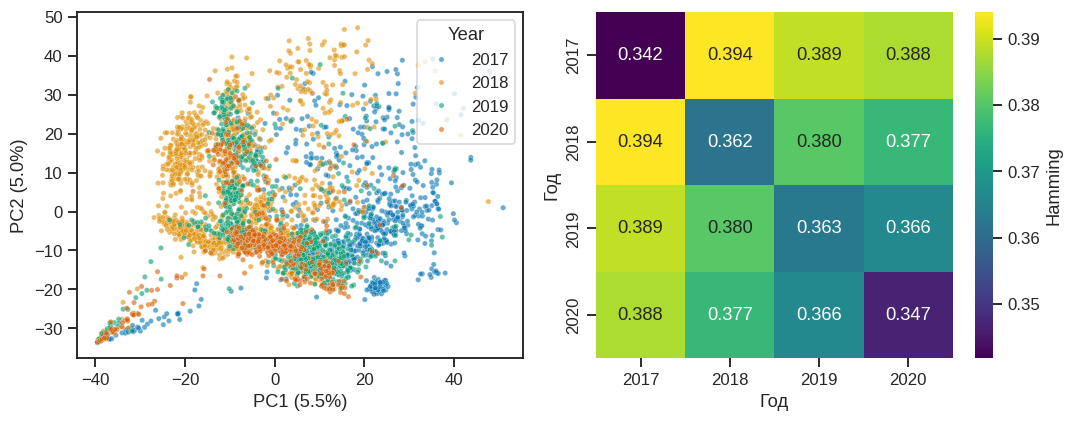

In [138]:
# T04
from IPython.display import Image
display(Image(filename=str(OUT/'figures/structure.png')))

In [151]:
# maize07_explained_v2: structure_interpretation
# T04: PCA и IBS описывают генотипы; это не оценка точности предсказания.
within=distance_summary.query('year1 == year2')
between=distance_summary.query('year1 < year2')
explain_result('Как читать PCA и генетические расстояния — T04',[
    f"Первая PC объясняет {pca.explained_variance_ratio_[0]:.1%} стандартизованной маркерной вариации, вторая — {pca.explained_variance_ratio_[1]:.1%}; первые десять вместе — {pca.explained_variance_ratio_[:10].sum():.1%}. Перекрытие точек на PC1/PC2 не означает, что генотипы одинаковы: часть различий лежит на других компонентах.",
    f"Среднее расстояние Hamming внутри годовых когорт: {within.hamming_mean.min():.3f}–{within.hamming_mean.max():.3f}; между когортами: {between.hamming_mean.min():.3f}–{between.hamming_mean.max():.3f}. Это описательная сводка всех пар, не проверка независимых семей.",
    'Для бинарных маркеров Hamming — доля несовпадающих состояний, а IBS здесь определена как 1−Hamming. Поэтому эти две матрицы не являются независимыми подтверждениями: они содержат одну информацию на противоположных шкалах.',
    'PCA стандартизует маркеры и использует все генотипы только для описания структуры. Обучающие модели по-прежнему оценивают свои преобразования только на train. IBS не доказывает родословную, а отсутствие семейных меток не позволяет проверить настоящее family-wise CV.'
])

### Как читать PCA и генетические расстояния — T04

Первая PC объясняет 5.5% стандартизованной маркерной вариации, вторая — 5.0%; первые десять вместе — 29.7%. Перекрытие точек на PC1/PC2 не означает, что генотипы одинаковы: часть различий лежит на других компонентах.

Среднее расстояние Hamming внутри годовых когорт: 0.342–0.363; между когортами: 0.366–0.394. Это описательная сводка всех пар, не проверка независимых семей.

Для бинарных маркеров Hamming — доля несовпадающих состояний, а IBS здесь определена как 1−Hamming. Поэтому эти две матрицы не являются независимыми подтверждениями: они содержат одну информацию на противоположных шкалах.

PCA стандартизует маркеры и использует все генотипы только для описания структуры. Обучающие модели по-прежнему оценивают свои преобразования только на train. IBS не доказывает родословную, а отсутствие семейных меток не позволяет проверить настоящее family-wise CV.

## 3. Общий код обучения — он находится прямо в ноутбуке

Следующие функции делают только явно описанные шаги; их определения видны целиком. `train_case` вызывает `fit` и `predict` выбранной модели, а `record_case` сохраняет прогнозы вместе с GID и считает метрики. Реализация самой модели импортируется из одноимённого файла `gp_models`.

- **GBLUP** — линейное геномное ядро. **RR-BLUP** — эквивалентная запись через эффекты маркеров; отдельно проверим совпадение, а не объявим их двумя независимыми конкурентами.
- **KBLUP** — нелинейное Gaussian-ядро; ширина — медиана положительных квадратов расстояний **train**.
- **BRR / BayesA** — Gibbs: 8000 шагов, 2000 burn-in, thin=5 (1200 сохранений). Для бинарных маркеров явно выбираем калибровку приора через сумму вариаций маркеров train. Старые вызовы модулей без этого аргумента сохраняют прежнюю калибровку.
- **Random forest** — адаптер к scikit-learn: 200 деревьев, leaf≥5, 30% признаков при выборе разделения.
- **Baseline** — среднее / фиксированные эффекты без маркеров.

r показывает ранжирование, RMSE и MAE — ошибку в единицах признака. **Предиктивный R² = 1−SSE/SST**, не квадрат r; он может быть отрицательным. Для постоянного прогноза r не определена (NaN). top-20% — вспомогательная метрика; у baseline равные прогнозы, поэтому её случайное разрешение ничьих не следует интерпретировать.

Фиксированные эффекты — свободное среднее и, при объединении групп, центрированные по train контрасты года/режима. Неизвестный уровень target имеет нулевой контраст. Ни среднее target, ни его фенотипы в обучение не входят. Память `kernel_cache` содержит только матрицы **этого запуска**, максимум четыре; старые файлы результатов не читаются.

In [109]:
# T02/T10
def records(years, trait, conditions, gids=None):
    """One row per observed phenotype; pooled regimes have two records/GID."""
    years = [years] if np.isscalar(years) else list(years)
    conditions = [conditions] if isinstance(conditions,str) else list(conditions)
    pieces = []
    for condition in conditions:
        col = f'{trait}_{condition}'
        mask = pheno.Year.isin(years)&pheno[col].notna()
        if gids is not None: mask &= pheno.GID.isin(gids)
        d = pheno.loc[mask,['row','GID','Year']].copy()
        d['Condition'],d['y'] = condition,pheno.loc[mask,col].to_numpy()
        pieces.append(d)
    return pd.concat(pieces,ignore_index=True)


def fixed_design(train, target):
    F,T,names = [np.ones(len(train))],[np.ones(len(target))],['intercept']
    for col in ['Year','Condition']:
        levels = sorted(train[col].unique())
        known = target[col].isin(levels).to_numpy()
        for level in levels[:-1]:
            freq = (train[col]==level).mean()
            F.append((train[col]==level).to_numpy(float)-freq)
            T.append(np.where(known,(target[col]==level).to_numpy(float)-freq,0.))
            names.append(f'{col}={level}')
    F,T = np.column_stack(F),np.column_stack(T)
    _,R,piv = qr(F,mode='economic',pivoting=True)
    rank = int(np.sum(np.abs(np.diag(R))>1e-10*max(1.,np.abs(R).max())))
    keep = sorted(piv[:rank])
    return F[:,keep],T[:,keep],[names[i] for i in keep]


def robust_keep(y):
    y = np.asarray(y,float)
    med = np.median(y)
    mad = np.median(np.abs(y-med))
    return np.ones(len(y),dtype=bool) if mad==0 else np.abs(.67448975*(y-med)/mad)<=4.5


def array_digest(*arrays):
    h = hashlib.sha256()
    for a in arrays:
        a = np.ascontiguousarray(a)
        h.update(str((a.shape,a.dtype)).encode()); h.update(a.tobytes())
    return h.hexdigest()

kernel_cache = OrderedDict()

def prepare_kernel(kind, train, target, F, maf=0.):
    """Only identical current-run kernels are reused; no responses are cached."""
    key = (kind,maf,array_digest(train.row.to_numpy(),target.row.to_numpy(),F))
    if key in kernel_cache:
        prepared = kernel_cache.pop(key); kernel_cache[key] = prepared
        return prepared,True
    A,B = X[train.row],X[target.row]
    freq = A.mean(axis=0)
    keep = (A.var(axis=0)>0)&(np.minimum(freq,1-freq)>=maf)
    if not keep.any(): raise ValueError('Фильтр удалил все маркеры.')
    fn = prepare_gblup if kind=='GBLUP' else prepare_kblup
    prepared = fn(A[:,keep],B[:,keep],F)
    prepared['outer_keep'] = keep
    kernel_cache[key] = prepared
    while len(kernel_cache)>4: kernel_cache.popitem(last=False)
    return prepared,False

In [110]:
# T02/T10
def train_case(train, target, models, meta, maf=0., robust=False, keep_trace=False):
    """The complete visible fit/predict logic for one train/test experiment."""
    train,target = train.copy().reset_index(drop=True),target.copy().reset_index(drop=True)
    assert not set(train.GID)&set(target.GID), 'Утечка GID train/test'
    assert train.y.notna().all() and target.y.notna().all()
    original_n = len(train)
    if robust: train = train.loc[robust_keep(train.y)].reset_index(drop=True)
    F,T,names = fixed_design(train,target)
    y = train.y.to_numpy(float)
    seed = int(meta.get('repeat',1))
    detail = dict(meta,train_n=train.GID.nunique(),train_records=len(train),test_n=len(target),
                  train_removed=original_n-len(train),maf=maf,robust=robust)
    key_text = json.dumps(detail,sort_keys=True,default=str)
    detail['case_id'] = str(meta['stage'])+'_'+hashlib.sha256((key_text+array_digest(train.row.to_numpy(),target.row.to_numpy())).encode()).hexdigest()[:16]
    result = dict(meta=detail,train=train,target=target,models={})
    for model in models:
        pre_seconds=fit_seconds=predict_seconds=0.
        reused=False
        info={}
        start = time.perf_counter()
        if model in ['GBLUP','KBLUP']:
            prepared,reused = prepare_kernel(model,train,target,F,maf)
            pre_seconds = time.perf_counter()-start
            t = time.perf_counter()
            if model=='GBLUP':
                fit = gblup_fit_reml(y,prepared['K'],F=F,eigen=prepared['eigen'],bounds=tuple(CONFIG['reml_log_lambda_bounds']))
            else:
                fit = kblup_fit(y,prepared,F=F,bounds=tuple(CONFIG['reml_log_lambda_bounds']))
            fit_seconds = time.perf_counter()-t
            t = time.perf_counter()
            if model=='GBLUP': pred = gblup_predict(fit,prepared['cross'],F_new=T)
            else: pred = kblup_predict(fit,prepared,F_new=T)
            genetic = prepared['cross']@fit['alpha']
            predict_seconds = time.perf_counter()-t
            info = {k:fit['vc'][k] for k in ['lam','sigma2_g','sigma2_e','h2','boundary']}
            info.update(n_markers=prepared['n_markers'],kernel_scale=prepared['scale'])
            if model=='KBLUP': info['bandwidth']=prepared['bandwidth']
        elif model in ['BRR','BayesA']:
            A,B = X[train.row],X[target.row]
            keep = A.var(axis=0)>0
            A,B = A[:,keep],B[:,keep]
            pre_seconds = time.perf_counter()-start
            t = time.perf_counter()
            if model=='BRR':
                if F.shape[1]!=1: raise ValueError('BRR здесь используется только со свободным средним.')
                fit = brr_fit(y,A,seed=seed,**CONFIG['gibbs'])
            else:
                fit = bayesa_fit(y,A,seed=seed,F=F,**CONFIG['gibbs'])
            fit_seconds = time.perf_counter()-t
            t = time.perf_counter()
            genetic = (B-A.mean(axis=0))@fit['beta']
            pred = (np.full(len(B),fit['mu']) if model=='BRR' else T@fit['beta_fixed'])+genetic
            predict_seconds = time.perf_counter()-t
            info = dict(n_markers=int(keep.sum()),sigma2_e=fit['sigma2_e'],prior_calibration=fit['prior_calibration'],n_saved=len(fit['trace']))
            if keep_trace: trace_store[(meta['trait'],model,seed)] = fit['trace'].copy()
        elif model=='Random forest':
            A,B = X[train.row],X[target.row]
            pre_seconds = time.perf_counter()-start
            t = time.perf_counter()
            fit = random_forest_fit(y,A,seed=seed,**CONFIG['forest'])
            fit_seconds = time.perf_counter()-t
            t = time.perf_counter()
            pred = random_forest_predict(fit,B)
            genetic = pred-y.mean()
            predict_seconds = time.perf_counter()-t
            info = dict(n_markers=fit['n_markers'])
        elif model=='Baseline':
            t = time.perf_counter()
            fixed = np.linalg.lstsq(F,y,rcond=None)[0]
            fit_seconds = time.perf_counter()-t
            t = time.perf_counter()
            pred,genetic = T@fixed,np.zeros(len(target))
            predict_seconds = time.perf_counter()-t
            info = dict(n_markers=0)
        else: raise ValueError(model)
        assert np.isfinite(pred).all()
        result['models'][model] = dict(predicted=pred,genetic_component=genetic,info=info,
                     preparation_seconds=pre_seconds,fit_seconds=fit_seconds,predict_seconds=predict_seconds,
                     preparation_reused=reused)
    return result

In [111]:
# T02/T10
def record_case(result, subset=None, extra=None, save_manifest=True):
    """Score new predictions, optionally on a matched target subset; no refitting."""
    target = result['target']
    take = np.arange(len(target)) if subset is None else np.asarray(subset,int)
    selected = target.iloc[take]
    meta = dict(result['meta'],**(extra or {}))
    meta['test_n'] = len(take)
    # Include evaluation identity when one fitted model is scored repeatedly.
    meta['case_id'] = meta['case_id']+'_'+array_digest(selected.row.to_numpy())[:8]
    for model,output in result['models'].items():
        obs = selected.y.to_numpy(float)
        pred = output['predicted'][take]
        score = regression_metrics(obs,pred)
        metrics_rows.append(dict(meta,model=model,**score,top20=topk_overlap(obs,pred),**output['info'],
                    preparation_seconds=output['preparation_seconds'],fit_seconds=output['fit_seconds'],
                    predict_seconds=output['predict_seconds'],preparation_reused=output['preparation_reused'],status='ok'))
        frame = selected[['GID','row','Year','Condition']].copy()
        frame['observed'],frame['predicted'] = obs,pred
        frame['genetic_component'] = output['genetic_component'][take]
        for key,value in dict(meta,model=model).items(): frame[key] = value
        prediction_parts.append(frame)
    if save_manifest:
        for role,frame in [('train',result['train']),('test',selected)]:
            m = frame[['GID','row','Year','Condition']].copy()
            for key,value in dict(meta,role=role).items(): m[key]=value
            manifest_parts.append(m)


def save_stage(label,started):
    """Write complete independent files; never append to an S3-backed file."""
    global active_seconds
    elapsed = time.perf_counter()-started
    active_seconds += elapsed
    stage_times.append(dict(part=label,seconds=elapsed,active_seconds=active_seconds))
    pd.DataFrame(metrics_rows).to_csv(OUT/'metrics_per_split.csv',index=False)
    preds = pd.concat(prediction_parts,ignore_index=True) if prediction_parts else pd.DataFrame()
    manifest = pd.concat(manifest_parts,ignore_index=True) if manifest_parts else pd.DataFrame()
    paths = []
    if len(preds):
        path = OUT/f'predictions_{label}.parquet'; preds.to_parquet(path,index=False); paths.append(path)
    if len(manifest):
        path = OUT/f'manifest_{label}.parquet'; manifest.to_parquet(path,index=False); paths.append(path)
    pd.DataFrame(stage_times).to_csv(OUT/'stage_times.csv',index=False)
    receipt = dict(run_id=RUN_ID,part=label,metric_rows=len(metrics_rows),prediction_rows=len(preds),manifest_rows=len(manifest),seconds=elapsed,
                   files={p.name:dict(bytes=p.stat().st_size,sha256=sha256(p)) for p in paths})
    (OUT/f'checkpoint_{label}.json').write_text(json.dumps(receipt,indent=2))
    prediction_parts.clear(); manifest_parts.clear(); kernel_cache.clear()
    print(f'{label}: {len(preds):,} новых прогнозов; метрик всего {len(metrics_rows):,}; {elapsed/60:.1f} мин; расчёт суммарно {active_seconds/60:.1f} мин.')
    if active_seconds>3*3600: raise RuntimeError('Достигнут согласованный предел активного расчёта; сохранённый этап завершён, требуется согласовать продолжение.')

### Численная самопроверка на реальных строках

До длинного расчёта проверяем равенство RR-BLUP/GBLUP с фиксированными эффектами, применение одной шкалы к train/cross и размер MCMC-буфера при неделимом числе шагов. Короткие цепи этой проверки не заменяют основные 8000 шагов.

In [112]:
# T02/T10
t0 = time.perf_counter()
small_train = records(2017,'GY','Optimal').iloc[:60].copy()
small_test = records(2017,'GY','Optimal').iloc[60:80].copy()
A,B = X[small_train.row,:100],X[small_test.row,:100]
Fcheck = np.column_stack([np.ones(60),(np.arange(60)%2)-.5])
Tcheck = np.column_stack([np.ones(20),(np.arange(20)%2)-.5])
check_pre = prepare_gblup(A,B,Fcheck)
check_fit = gblup_fit_reml(small_train.y.to_numpy(),check_pre['K'],Fcheck,check_pre['eigen'])
Z,Znew = A[:,check_pre['keep']]-check_pre['mean'],B[:,check_pre['keep']]-check_pre['mean']
ridge = rrblup_fit(small_train.y.to_numpy(),Z,check_fit['vc']['lam']*check_pre['scale'],Fcheck)
check_diff = float(np.max(np.abs(gblup_predict(check_fit,check_pre['cross'],Tcheck)-predict_gebv(ridge,Znew,Tcheck))))
assert check_diff<1e-7
for fn in [brr_fit,bayesa_fit]:
    test_fit = fn(small_train.y.to_numpy(),A,n_iter=202,burn_in=50,thin=5,prior_calibration='marker_variance',seed=1)
    assert len(test_fit['trace'])==31 and np.isfinite(test_fit['trace']).all()
# A short real-data smoke test exercises mixed regimes/years, filters and unknown target levels.
old_config = CONFIG['gibbs'].copy()
CONFIG['gibbs'] = dict(old_config,n_iter=202,burn_in=50,thin=5)
try:
    smoke_cases = [
        (records(2017,'GY','Optimal').iloc[:60], records(2017,'GY','Optimal').iloc[60:80], MODELS,False,.0),
        (records(2017,'GY',CONDITIONS).query('GID in @small_train.GID'),small_test,KERNEL_MODELS,False,.0),
        (records([2017,2018],'GY','Optimal').iloc[::25].head(80),records(2020,'GY','Optimal').head(20),KERNEL_MODELS,False,.0),
        (small_train,small_test,['GBLUP','Baseline'],True,.2)]
    for i,(a,b,models,robust,maf) in enumerate(smoke_cases):
        smoke = train_case(a,b,models,dict(stage='check',trait='GY',condition='Optimal',year=2020,repeat=1,scenario=str(i)),robust=robust,maf=maf)
        assert all(np.isfinite(o['predicted']).all() for o in smoke['models'].values())
finally:
    CONFIG['gibbs'] = old_config
    kernel_cache.clear()
print('Проверки пройдены; max |RR−GBLUP| =',check_diff)
active_seconds += time.perf_counter()-t0

Проверки пройдены; max |RR−GBLUP| = 6.217248937900877e-15


<a id="tz-T10"></a>
## Что означают десять повторов — T10

| Блок | Train/test и модели | Что меняется между повторами | Что означает разброс |
|---|---|---|---|
| A | Внутри года/режима, 70/30; GBLUP, KBLUP, BRR, BayesA, лес, baseline | 10 разбиений GID, модели переобучаются | Чувствительность к составу train/test |
| B/D | Парно полные GID, три сценария; GBLUP, KBLUP, baseline | 10 согласованных разбиений, переобучение каждого сценария | В каждом повторе одинаковые train-GID и test-GID во всех трёх вариантах |
| C | Другой год или остальные три года; GBLUP, KBLUP, baseline | Train фиксирован; полный target и 10 его 85%-подвыборок | Чувствительность оценки к test, **не** 10 переобучений |
| E | Прошлые годы ±73 линии 2020; GBLUP, KBLUP, baseline | 10 разделений 486 на 73 reserve и 413 test | Состав test и доступных локальных линий; local0-train фиксирован |
| F | Исторический train, target=2020; GBLUP, baseline | 10 одинаковых 85%-target; nearest/farthest фиксируют train, random меняет train; all переиспользует одну модель | Смесь разных источников вариации; повторы зависимы |
| G | Разбиения A для 2020; GBLUP, baseline | 10 разбиений и train-only фильтрация | Test одинаков для всех фильтров и совпадает с A |

Сравнения согласованы **внутри** своей постановки. Это не один общий test для всех букв:
в A доступны все валидные фенотипы группы, в B/D — только парно полные; E — 413 target, F — 85% target.
Между GY/PH сохраняется правило split и seed, но при разных пропусках фактические GID могут отличаться.
Объединять SD этих блоков в одну «ошибку эксперимента» нельзя.

Все четыре метрики считаются на test. **r** — линейная связь наблюдений и прогнозов, не проверка правильной абсолютной шкалы;
**RMSE** сильнее реагирует на крупные ошибки, **MAE** — средняя абсолютная ошибка в тех же единицах;
**R² = 1−SSE/SST** может быть отрицательным, если хуже константы, равной среднему test.
Последнее среднее используется только при оценке, не для обучения baseline и не для калибровки прогнозов.

<a id="tz-T02"></a>
<a id="tz-T06"></a>
## A. Прогноз внутри года и режима

Для каждой пары год/режим и обоих признаков делаем 10 разбиений 70/30 (seed=1…10). Все модели сравниваются на одинаковых GID. Пропущенные фенотипы исключаются **только из соответствующего признака/режима**. Вариация между разбиениями показывает чувствительность к выбору обучающих линий; это не доверительный интервал независимых полевых опытов.

В восьми следующих ячейках видны выбор данных, цикл повторов и вызовы обучения. `train_case` выше содержит сами fit/predict. Длинные части разделены по годам/режимам, чтобы можно было видеть прогресс и сохранять результаты.

**Как читать результат:** далее восемь обучающих ячеек, затем сводка и панели отдельно для GY и PH.
В каждой панели сравнивайте модели одного цвета (одного года); полосы — SD десяти разбиений этой группы.
Это сравнение заранее заданных настроек, не доказательство глобального превосходства одного класса моделей.


In [113]:
# T02/T06/T10
started = time.perf_counter()
year,condition = 2017,'Optimal'
for repeat in CONFIG['seeds']:
    for trait in TRAITS:
        data = records(year,trait,condition)
        tr,te = next(random_splits(len(data),train_frac=CONFIG['train_fraction'],n_reps=1,seed=repeat))
        result = train_case(data.iloc[tr],data.iloc[te],MODELS,dict(stage='A',trait=trait,condition=condition,year=year,repeat=repeat,scenario='within',resample='split'))
        record_case(result)
    print(f'{year} {condition}: повтор {repeat}/10',flush=True)
save_stage('A_2017_Optimal',started)

2017 Optimal: повтор 1/10


2017 Optimal: повтор 2/10


2017 Optimal: повтор 3/10


2017 Optimal: повтор 4/10


2017 Optimal: повтор 5/10


2017 Optimal: повтор 6/10


2017 Optimal: повтор 7/10


2017 Optimal: повтор 8/10


2017 Optimal: повтор 9/10


2017 Optimal: повтор 10/10


A_2017_Optimal: 32,400 новых прогнозов; метрик всего 120; 8.7 мин; расчёт суммарно 8.8 мин.


In [114]:
# T02/T06/T10
started = time.perf_counter()
year,condition = 2017,'Drought'
for repeat in CONFIG['seeds']:
    for trait in TRAITS:
        data = records(year,trait,condition)
        tr,te = next(random_splits(len(data),train_frac=CONFIG['train_fraction'],n_reps=1,seed=repeat))
        result = train_case(data.iloc[tr],data.iloc[te],MODELS,dict(stage='A',trait=trait,condition=condition,year=year,repeat=repeat,scenario='within',resample='split'))
        record_case(result)
    print(f'{year} {condition}: повтор {repeat}/10',flush=True)
save_stage('A_2017_Drought',started)

2017 Drought: повтор 1/10


2017 Drought: повтор 2/10


2017 Drought: повтор 3/10


2017 Drought: повтор 4/10


2017 Drought: повтор 5/10


2017 Drought: повтор 6/10


2017 Drought: повтор 7/10


2017 Drought: повтор 8/10


2017 Drought: повтор 9/10


2017 Drought: повтор 10/10


A_2017_Drought: 32,400 новых прогнозов; метрик всего 240; 8.7 мин; расчёт суммарно 17.5 мин.


In [115]:
# T02/T06/T10
started = time.perf_counter()
year,condition = 2018,'Optimal'
for repeat in CONFIG['seeds']:
    for trait in TRAITS:
        data = records(year,trait,condition)
        tr,te = next(random_splits(len(data),train_frac=CONFIG['train_fraction'],n_reps=1,seed=repeat))
        result = train_case(data.iloc[tr],data.iloc[te],MODELS,dict(stage='A',trait=trait,condition=condition,year=year,repeat=repeat,scenario='within',resample='split'),keep_trace=(repeat==1))
        record_case(result)
    print(f'{year} {condition}: повтор {repeat}/10',flush=True)
save_stage('A_2018_Optimal',started)

2018 Optimal: повтор 1/10


2018 Optimal: повтор 2/10


2018 Optimal: повтор 3/10


2018 Optimal: повтор 4/10


2018 Optimal: повтор 5/10


2018 Optimal: повтор 6/10


2018 Optimal: повтор 7/10


2018 Optimal: повтор 8/10


2018 Optimal: повтор 9/10


2018 Optimal: повтор 10/10


A_2018_Optimal: 51,000 новых прогнозов; метрик всего 360; 13.1 мин; расчёт суммарно 30.7 мин.


In [116]:
# T02/T06/T10
started = time.perf_counter()
year,condition = 2018,'Drought'
for repeat in CONFIG['seeds']:
    for trait in TRAITS:
        data = records(year,trait,condition)
        tr,te = next(random_splits(len(data),train_frac=CONFIG['train_fraction'],n_reps=1,seed=repeat))
        result = train_case(data.iloc[tr],data.iloc[te],MODELS,dict(stage='A',trait=trait,condition=condition,year=year,repeat=repeat,scenario='within',resample='split'))
        record_case(result)
    print(f'{year} {condition}: повтор {repeat}/10',flush=True)
save_stage('A_2018_Drought',started)

2018 Drought: повтор 1/10


2018 Drought: повтор 2/10


2018 Drought: повтор 3/10


2018 Drought: повтор 4/10


2018 Drought: повтор 5/10


2018 Drought: повтор 6/10


2018 Drought: повтор 7/10


2018 Drought: повтор 8/10


2018 Drought: повтор 9/10


2018 Drought: повтор 10/10


A_2018_Drought: 51,000 новых прогнозов; метрик всего 480; 13.1 мин; расчёт суммарно 43.7 мин.


In [117]:
# T02/T06/T10
started = time.perf_counter()
year,condition = 2019,'Optimal'
for repeat in CONFIG['seeds']:
    for trait in TRAITS:
        data = records(year,trait,condition)
        tr,te = next(random_splits(len(data),train_frac=CONFIG['train_fraction'],n_reps=1,seed=repeat))
        result = train_case(data.iloc[tr],data.iloc[te],MODELS,dict(stage='A',trait=trait,condition=condition,year=year,repeat=repeat,scenario='within',resample='split'))
        record_case(result)
    print(f'{year} {condition}: повтор {repeat}/10',flush=True)
save_stage('A_2019_Optimal',started)

2019 Optimal: повтор 1/10


2019 Optimal: повтор 2/10


2019 Optimal: повтор 3/10


2019 Optimal: повтор 4/10


2019 Optimal: повтор 5/10


2019 Optimal: повтор 6/10


2019 Optimal: повтор 7/10


2019 Optimal: повтор 8/10


2019 Optimal: повтор 9/10


2019 Optimal: повтор 10/10


A_2019_Optimal: 26,040 новых прогнозов; метрик всего 600; 7.4 мин; расчёт суммарно 51.1 мин.


In [118]:
# T02/T06/T10
started = time.perf_counter()
year,condition = 2019,'Drought'
for repeat in CONFIG['seeds']:
    for trait in TRAITS:
        data = records(year,trait,condition)
        tr,te = next(random_splits(len(data),train_frac=CONFIG['train_fraction'],n_reps=1,seed=repeat))
        result = train_case(data.iloc[tr],data.iloc[te],MODELS,dict(stage='A',trait=trait,condition=condition,year=year,repeat=repeat,scenario='within',resample='split'))
        record_case(result)
    print(f'{year} {condition}: повтор {repeat}/10',flush=True)
save_stage('A_2019_Drought',started)

2019 Drought: повтор 1/10


2019 Drought: повтор 2/10


2019 Drought: повтор 3/10


2019 Drought: повтор 4/10


2019 Drought: повтор 5/10


2019 Drought: повтор 6/10


2019 Drought: повтор 7/10


2019 Drought: повтор 8/10


2019 Drought: повтор 9/10


2019 Drought: повтор 10/10


A_2019_Drought: 25,920 новых прогнозов; метрик всего 720; 7.4 мин; расчёт суммарно 58.5 мин.


In [119]:
# T02/T06/T10
started = time.perf_counter()
year,condition = 2020,'Optimal'
for repeat in CONFIG['seeds']:
    for trait in TRAITS:
        data = records(year,trait,condition)
        tr,te = next(random_splits(len(data),train_frac=CONFIG['train_fraction'],n_reps=1,seed=repeat))
        result = train_case(data.iloc[tr],data.iloc[te],MODELS,dict(stage='A',trait=trait,condition=condition,year=year,repeat=repeat,scenario='within',resample='split'))
        record_case(result)
    print(f'{year} {condition}: повтор {repeat}/10',flush=True)
save_stage('A_2020_Optimal',started)

2020 Optimal: повтор 1/10


2020 Optimal: повтор 2/10


2020 Optimal: повтор 3/10


2020 Optimal: повтор 4/10


2020 Optimal: повтор 5/10


2020 Optimal: повтор 6/10


2020 Optimal: повтор 7/10


2020 Optimal: повтор 8/10


2020 Optimal: повтор 9/10


2020 Optimal: повтор 10/10


A_2020_Optimal: 17,520 новых прогнозов; метрик всего 840; 5.8 мин; расчёт суммарно 64.3 мин.


In [120]:
# T02/T06/T10
started = time.perf_counter()
year,condition = 2020,'Drought'
for repeat in CONFIG['seeds']:
    for trait in TRAITS:
        data = records(year,trait,condition)
        tr,te = next(random_splits(len(data),train_frac=CONFIG['train_fraction'],n_reps=1,seed=repeat))
        result = train_case(data.iloc[tr],data.iloc[te],MODELS,dict(stage='A',trait=trait,condition=condition,year=year,repeat=repeat,scenario='within',resample='split'))
        record_case(result)
    print(f'{year} {condition}: повтор {repeat}/10',flush=True)
save_stage('A_2020_Drought',started)

2020 Drought: повтор 1/10


2020 Drought: повтор 2/10


2020 Drought: повтор 3/10


2020 Drought: повтор 4/10


2020 Drought: повтор 5/10


2020 Drought: повтор 6/10


2020 Drought: повтор 7/10


2020 Drought: повтор 8/10


2020 Drought: повтор 9/10


2020 Drought: повтор 10/10


A_2020_Drought: 17,520 новых прогнозов; метрик всего 960; 6.0 мин; расчёт суммарно 70.3 мин.


,trait,condition,year,model,r_mean,r_sd,rmse_mean,mae_mean,r2_mean,n_splits
0,GY,Drought,2017,BRR,0.618,0.028,0.645,0.518,0.377,10
1,GY,Drought,2017,Baseline,NaN,NaN,0.820,0.660,-0.007,10
2,GY,Drought,2017,BayesA,0.587,0.028,0.674,0.538,0.320,10
3,GY,Drought,2017,GBLUP,0.618,0.028,0.644,0.517,0.378,10
4,GY,Drought,2017,KBLUP,0.620,0.029,0.643,0.516,0.380,10
...,...,...,...,...,...,...,...,...,...,...
91,PH,Optimal,2020,Baseline,NaN,NaN,12.549,10.282,-0.013,10
92,PH,Optimal,2020,BayesA,0.660,0.031,9.551,7.505,0.413,10
93,PH,Optimal,2020,GBLUP,0.685,0.035,9.150,7.244,0.461,10
94,PH,Optimal,2020,KBLUP,0.688,0.036,9.110,7.219,0.466,10


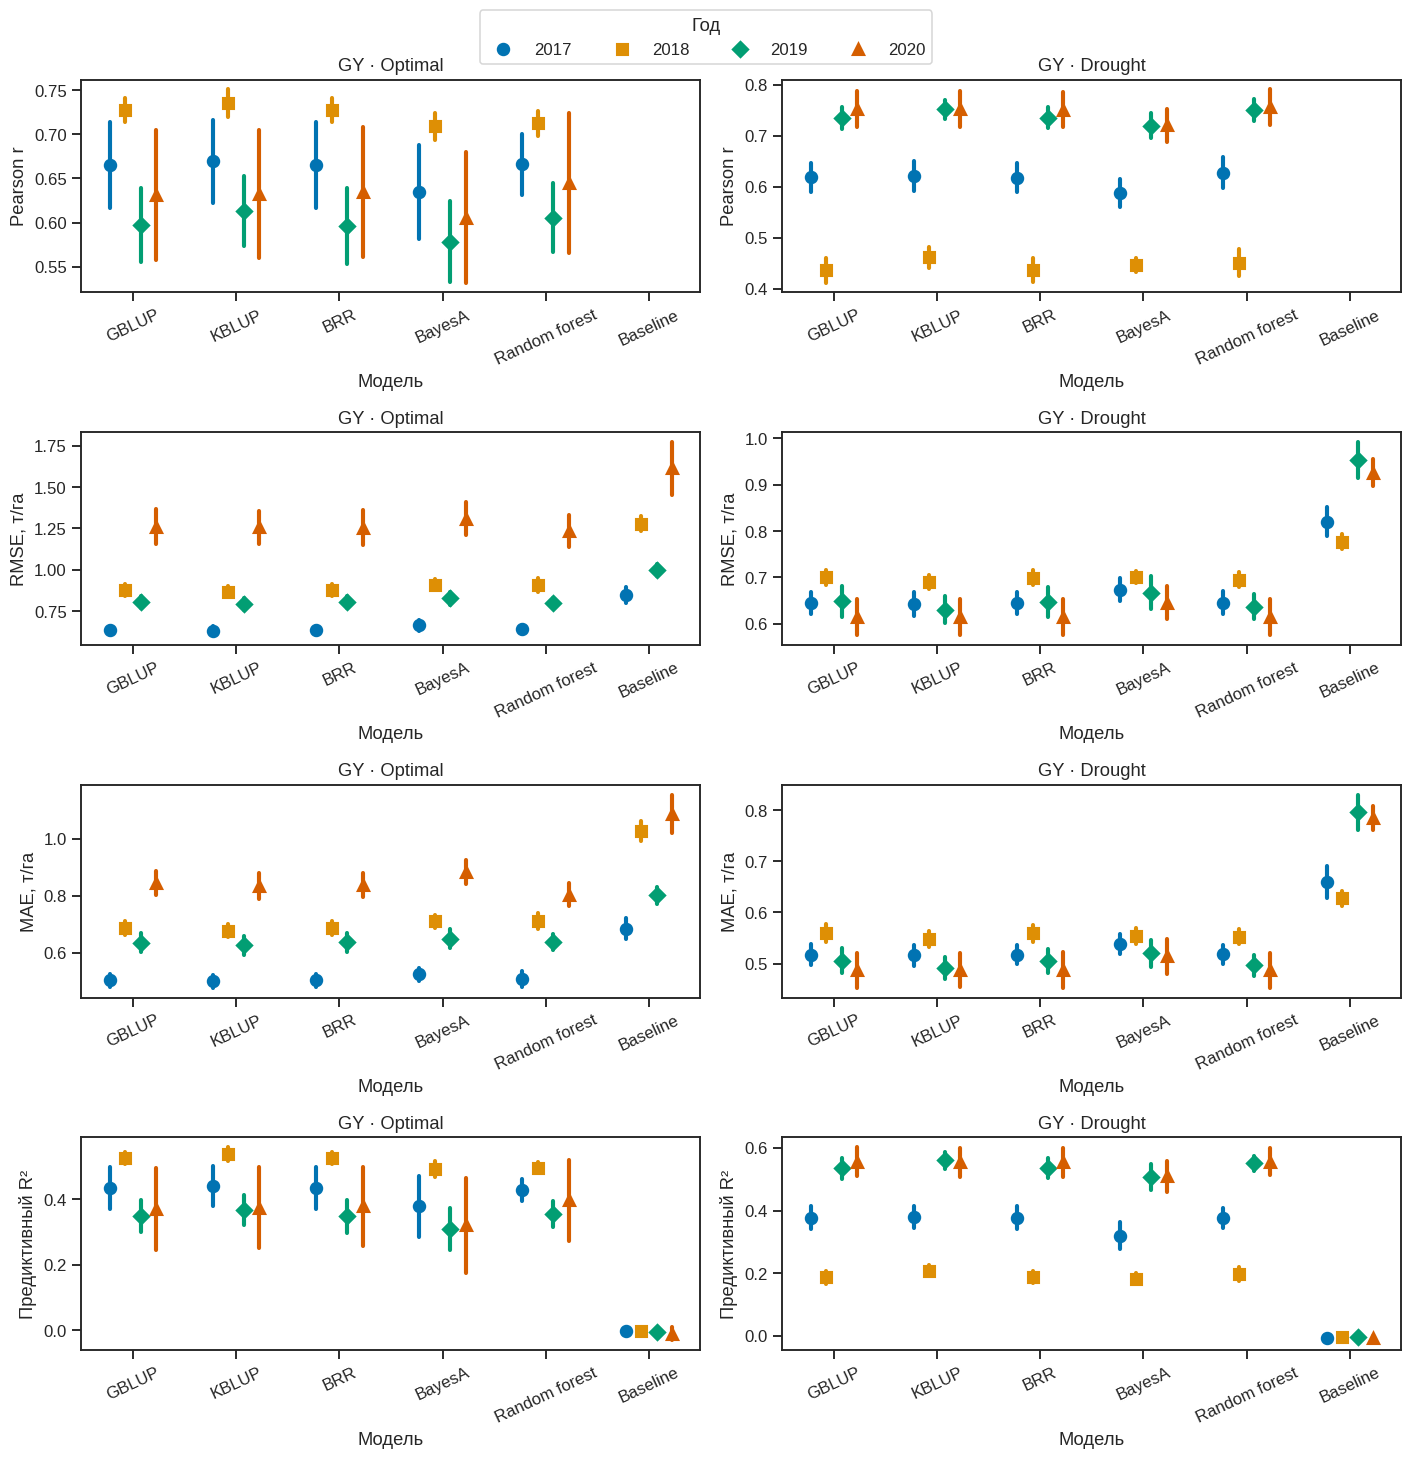

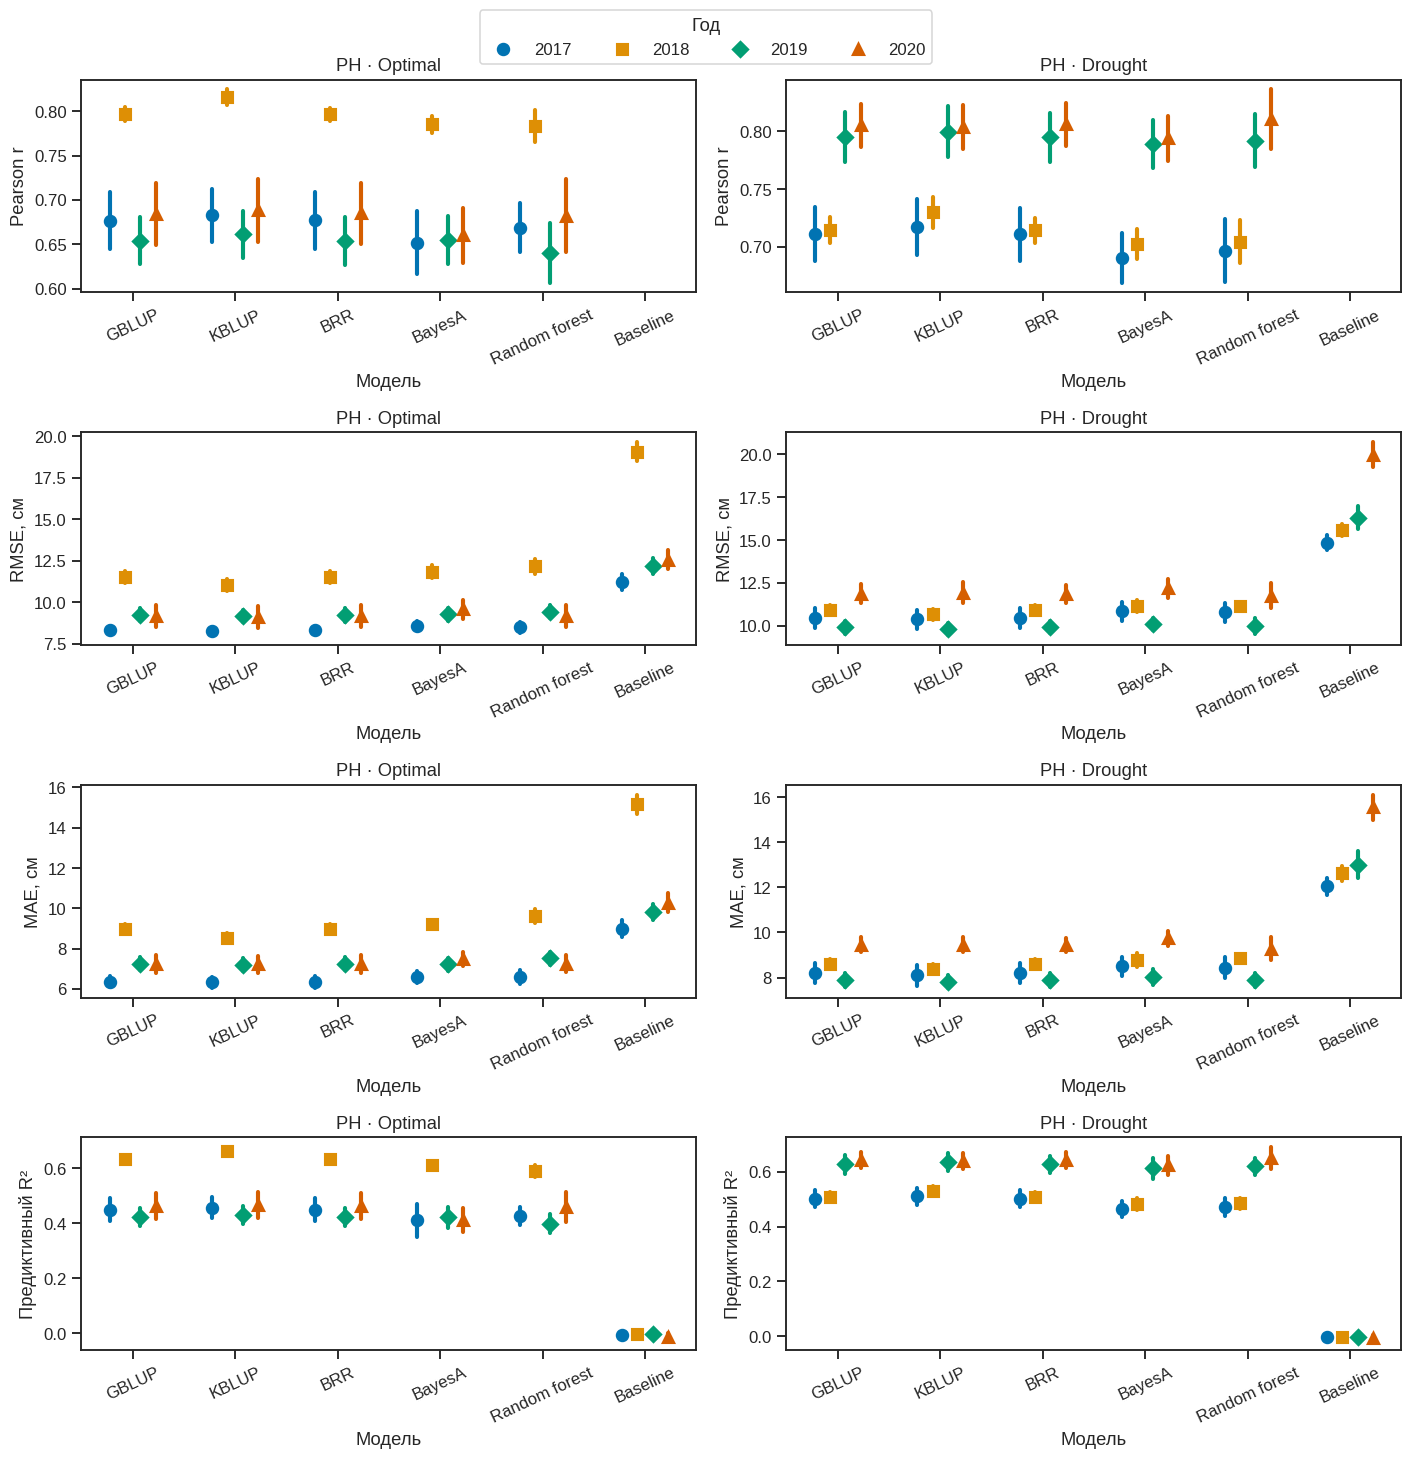

In [152]:
# maize07_explained_v2: A_four_metrics
# T02/T06/T10: все методы оцениваются на тех же test-GID в каждой группе.
A_metrics=pd.DataFrame(metrics_rows).query("stage == 'A'").copy()
A_summary=A_metrics.groupby(['trait','condition','year','model']).agg(r_mean=('r','mean'),r_sd=('r','std'),rmse_mean=('rmse','mean'),mae_mean=('mae','mean'),r2_mean=('r2','mean'),n_splits=('repeat','nunique')).reset_index()
A_summary.to_csv(OUT/'A_summary.csv',index=False)
display(A_summary.round(3))
for trait in TRAITS:
    unit='т/га' if trait=='GY' else 'см'
    fig,axes=plt.subplots(4,2,figsize=(13,13))
    for row,metric in enumerate(['r','rmse','mae','r2']):
        for column,condition in enumerate(CONDITIONS):
            ax=axes[row,column]
            d=A_metrics.query('trait == @trait and condition == @condition')
            sns.pointplot(data=d,x='model',y=metric,hue='year',order=MODELS,hue_order=YEARS,errorbar='sd',dodge=.45,palette='colorblind',ax=ax,markers=['o','s','D','^'],linestyles='none')
            label=metric_names[metric]+(f', {unit}' if metric in ['rmse','mae'] else '')
            ax.set(title=f'{trait} · {condition}',xlabel='Модель',ylabel=label)
            ax.tick_params(axis='x',rotation=25)
            if row==0 and column==0: handles,labels=ax.get_legend_handles_labels()
            if ax.get_legend() is not None: ax.get_legend().remove()
    fig.legend(handles,labels,title='Год',loc='upper center',ncol=4,bbox_to_anchor=(.5,1.025))
    show_explained_figure(fig,f'A_four_metrics_{trait}')

In [153]:
# maize07_explained_v2: A_interpretation
# T02/T06: сравнение методов — не утверждение о значимом превосходстве.
paragraphs=[]
for trait in TRAITS:
    scores=A_metrics.query("trait == @trait and model != 'Baseline'").groupby('model')[['r','rmse','mae','r2']].mean()
    leader=scores.r.idxmax()
    paragraphs.append(f"**{trait}:** средняя r по восьми группам (четыре года × два режима) у {leader} равна {scores.loc[leader,'r']:.3f}, у GBLUP — {scores.loc['GBLUP','r']:.3f}. Это удобная описательная сводка, а не отдельный статистический тест и не одна независимая внешняя выборка.")
paragraphs.extend([
    'На графиках сравнивайте методы внутри одного года, режима и признака. Точка — среднее по 10 train/test-разбиениям, полоса — их SD; SD не является 95%-м доверительным интервалом. RMSE и MAE меньше — лучше; r и предиктивный R² больше — лучше.',
    '**Предиктивный R² = 1−SSE/SST**, а не r². Отрицательное значение означает, что сумма квадратов ошибок больше, чем при постоянном прогнозе, равном среднему данного test. Это диагностическое сравнение, а не разрешение использовать среднее test для обучения. У постоянного baseline корреляция r не определена.',
    'KBLUP использует нелинейное ядро, лес — набор деревьев. Более сложная модель не обязана выигрывать во всех группах. RR-BLUP и GBLUP при согласованной λ эквивалентны, поэтому RR-BLUP не добавлен как ещё один независимый конкурент.',
    'BRR и BayesA здесь сравниваются при зафиксированной длине цепей. Ниже у дисперсий эффектов BRR будет отмечен недостаточный ESS; результаты нельзя описывать как доказанную сходимость всех параметров.'
])
explain_result('Как читать сравнение методов — T02/T06',paragraphs)

### Как читать сравнение методов — T02/T06

**GY:** средняя r по восьми группам (четыре года × два режима) у KBLUP равна 0.654, у GBLUP — 0.645. Это удобная описательная сводка, а не отдельный статистический тест и не одна независимая внешняя выборка.

**PH:** средняя r по восьми группам (четыре года × два режима) у KBLUP равна 0.737, у GBLUP — 0.730. Это удобная описательная сводка, а не отдельный статистический тест и не одна независимая внешняя выборка.

На графиках сравнивайте методы внутри одного года, режима и признака. Точка — среднее по 10 train/test-разбиениям, полоса — их SD; SD не является 95%-м доверительным интервалом. RMSE и MAE меньше — лучше; r и предиктивный R² больше — лучше.

**Предиктивный R² = 1−SSE/SST**, а не r². Отрицательное значение означает, что сумма квадратов ошибок больше, чем при постоянном прогнозе, равном среднему данного test. Это диагностическое сравнение, а не разрешение использовать среднее test для обучения. У постоянного baseline корреляция r не определена.

KBLUP использует нелинейное ядро, лес — набор деревьев. Более сложная модель не обязана выигрывать во всех группах. RR-BLUP и GBLUP при согласованной λ эквивалентны, поэтому RR-BLUP не добавлен как ещё один независимый конкурент.

BRR и BayesA здесь сравниваются при зафиксированной длине цепей. Ниже у дисперсий эффектов BRR будет отмечен недостаточный ESS; результаты нельзя описывать как доказанную сходимость всех параметров.

<a id="tz-T09"></a>
### Наблюдаемый признак и оценённая генетическая компонента — T09

**Вопрос:** связана ли оценённая генетическая компонента с наблюдаемым признаком?
Заранее выбираем GBLUP, 2020 и первый split, не самый удачный результат.
В четырёх панелях **x — наблюдаемый GY/PH, y — оценённая генетическая компонента**, линия — OLS `BV ~ observed`;
r показана на графике, r и n — в таблице.
OLS здесь только описывает scatter: она не переобучает геномную модель и не корректирует тестовые прогнозы.
Для PH это аналогичный scatter высоты, а не урожайности. Истинная BV в этих данных не наблюдается.

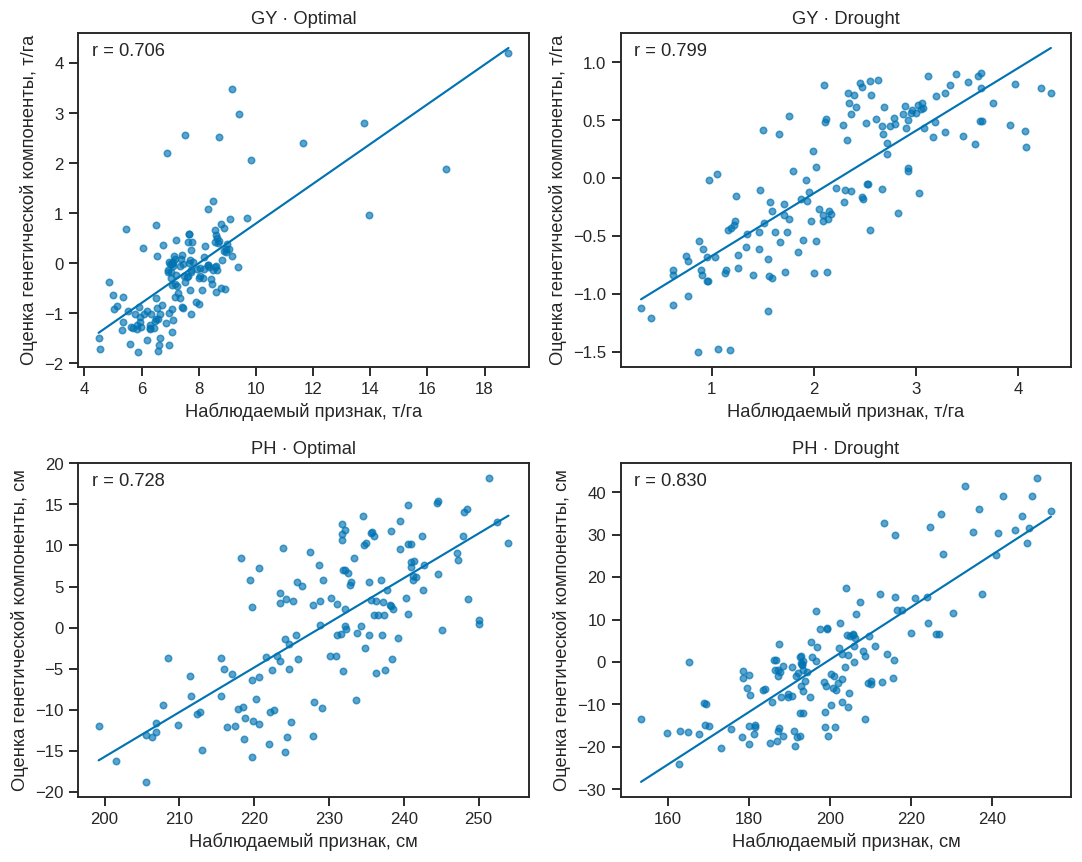

,trait,condition,year,repeat,model,n,r,slope,intercept
0,GY,Optimal,2020,1,GBLUP,146,0.7064,0.3968,-3.1725
1,GY,Drought,2020,1,GBLUP,146,0.7995,0.5422,-1.2171
2,PH,Optimal,2020,1,GBLUP,146,0.7283,0.5436,-124.4386
3,PH,Drought,2020,1,GBLUP,146,0.8302,0.6184,-123.0927


### Что означает BV–фенотип scatter — T09

Каждая точка — GID из test первого заранее выбранного разбиения 2020 года. Для GY это урожайность против оценённой BV-компоненты; для PH — аналогичный график высоты. Истинная племенная ценность в CSV неизвестна: по вертикали стоит оценка модели, а не измеренная BV.

Прямая — описательная OLS-регрессия оценки генетической компоненты на наблюдаемый признак. Её считали после получения test-прогнозов и не использовали для исправления этих прогнозов. r описывает линейную связь; наклон не обязан быть равен 1.

Один scatter иллюстрирует связь на конкретном split; оценка устойчивости метода берётся из всех 10 разбиений в разделе A, а не из визуального впечатления об одной панели.

In [154]:
# maize07_explained_v2: BV_scatter
# T09: BV по вертикали, наблюдаемый признак по горизонтали; только held-out GID.
scatter=pd.concat([pd.read_parquet(OUT/f'predictions_A_2020_{c}.parquet') for c in CONDITIONS],ignore_index=True)
scatter=scatter.query("repeat == 1 and model == 'GBLUP'")
scatter_statistics=[]
fig,axes=plt.subplots(2,2,figsize=(10,8))
for ax,(trait,condition) in zip(axes.flat,product(TRAITS,CONDITIONS)):
    d=scatter.query('trait == @trait and condition == @condition')
    observed=d.observed.to_numpy(float)
    bv=d.genetic_component.to_numpy(float)
    fit_line=stats.linregress(observed,bv)
    independent_r=float(np.corrcoef(observed,bv)[0,1])
    assert np.isclose(fit_line.rvalue,independent_r,atol=1e-12)
    saved_r=A_metrics.query('trait == @trait and condition == @condition and year == 2020 and repeat == 1 and model == "GBLUP"').r.iloc[0]
    assert np.isclose(saved_r,independent_r,atol=1e-12)
    row_indices=d['row'].to_numpy(int)
    np.testing.assert_array_equal(pheno.GID.to_numpy()[row_indices],d.GID.to_numpy())
    np.testing.assert_allclose(pheno[f'{trait}_{condition}'].to_numpy()[row_indices],observed,rtol=0,atol=0)
    sns.regplot(data=d,x='observed',y='genetic_component',ci=None,scatter_kws={'s':18,'alpha':.65},line_kws={'linewidth':1.4},ax=ax)
    unit='т/га' if trait=='GY' else 'см'
    ax.set(title=f'{trait} · {condition}',xlabel=f'Наблюдаемый признак, {unit}',ylabel=f'Оценка генетической компоненты, {unit}')
    ax.text(.03,.97,f'r = {independent_r:.3f}',transform=ax.transAxes,ha='left',va='top')
    scatter_statistics.append(dict(trait=trait,condition=condition,year=2020,repeat=1,model='GBLUP',n=len(d),r=independent_r,slope=fit_line.slope,intercept=fit_line.intercept))
show_explained_figure(fig,'A_genetic_phenotype')
scatter_statistics=pd.DataFrame(scatter_statistics)
scatter_statistics.to_csv(OUT/'BV_scatter_statistics.csv',index=False)
display(scatter_statistics.round(4))
explain_result('Что означает BV–фенотип scatter — T09',[
    'Каждая точка — GID из test первого заранее выбранного разбиения 2020 года. Для GY это урожайность против оценённой BV-компоненты; для PH — аналогичный график высоты. Истинная племенная ценность в CSV неизвестна: по вертикали стоит оценка модели, а не измеренная BV.',
    'Прямая — описательная OLS-регрессия оценки генетической компоненты на наблюдаемый признак. Её считали после получения test-прогнозов и не использовали для исправления этих прогнозов. r описывает линейную связь; наклон не обязан быть равен 1.',
    'Один scatter иллюстрирует связь на конкретном split; оценка устойчивости метода берётся из всех 10 разбиений в разделе A, а не из визуального впечатления об одной панели.'
])

<a id="tz-T03"></a>
## B/D. Другой режим и объединение режимов

Для каждого признака берём GID с наблюдениями **в обоих режимах**. Одно разбиение GID используется для трёх вариантов:

1. **opposite (B)**: train только в противоположном режиме;
2. **single (D)**: train только в целевом режиме;
3. **pooled (D)**: те же train-GID, но два режима как две записи, с фиксированным эффектом режима.

Test всегда один и тот же, в целевом режиме; его GID не встречаются в train ни под каким режимом. В pooled общий генетический компонент; это **не полноценная модель G×E**. Если перенос режима меняет среднее, B закономерно может иметь большую RMSE даже при положительной r.

In [122]:
# T03/T10
paired_checks = []
for year in YEARS:
    started = time.perf_counter()
    for condition,repeat,trait in product(CONDITIONS,CONFIG['seeds'],TRAITS):
        opposite = next(c for c in CONDITIONS if c!=condition)
        complete = pheno.loc[(pheno.Year==year)&pheno[[f'{trait}_{c}' for c in CONDITIONS]].notna().all(axis=1),'GID'].to_numpy()
        tr,te = next(random_splits(len(complete),train_frac=CONFIG['train_fraction'],n_reps=1,seed=repeat))
        train_ids,test_ids = complete[tr],complete[te]
        target = records(year,trait,condition,test_ids)
        observed_sets = []
        for scenario,stage,training_conditions in [('opposite','B',opposite),('single','D',condition),('pooled','D',CONDITIONS)]:
            train = records(year,trait,training_conditions,train_ids)
            result = train_case(train,target,KERNEL_MODELS,dict(stage=stage,trait=trait,condition=condition,year=year,repeat=repeat,scenario=scenario,resample='split'))
            record_case(result)
            observed_sets.append((set(result['train'].GID),set(result['target'].GID)))
        assert all(s==observed_sets[0] for s in observed_sets)
        assert not observed_sets[0][0]&observed_sets[0][1]
        paired_checks.append(dict(year=year,trait=trait,condition=condition,repeat=repeat,train_n=len(train_ids),test_n=len(test_ids),matched=True))
    save_stage(f'BD_{year}',started)
assert len(paired_checks)==160 and all(x['matched'] for x in paired_checks)
pd.DataFrame(paired_checks).to_csv(OUT/'BD_matched_gid_checks.csv',index=False)
print('Подтверждены 160 совпадающих троек B/D.')

BD_2017: 97,200 новых прогнозов; метрик всего 1,320; 0.4 мин; расчёт суммарно 70.7 мин.


BD_2018: 153,000 новых прогнозов; метрик всего 1,680; 0.9 мин; расчёт суммарно 71.6 мин.


BD_2019: 77,760 новых прогнозов; метрик всего 2,040; 0.3 мин; расчёт суммарно 71.9 мин.


BD_2020: 52,560 новых прогнозов; метрик всего 2,400; 0.1 мин; расчёт суммарно 72.1 мин.
Подтверждены 160 совпадающих троек B/D.


In [123]:
# T03/T10
BD = pd.DataFrame(metrics_rows).query("stage in ['B','D']").copy()
BD_summary = BD.groupby(['trait','condition','year','scenario','model'])[['r','rmse','mae','r2']].agg(['mean','std'])
BD_summary.to_csv(OUT/'BD_summary.csv')
# The paired difference is calculated within year/trait/regime/repeat/model.
paired = BD.pivot(index=['trait','condition','year','repeat','model'],columns='scenario',values=['r','rmse','mae','r2'])
deltas = pd.DataFrame(index=paired.index)
for metric in ['r','rmse','mae','r2']:
    deltas[f'{metric}_pooled_minus_single'] = paired[(metric,'pooled')]-paired[(metric,'single')]
    deltas[f'{metric}_single_minus_opposite'] = paired[(metric,'single')]-paired[(metric,'opposite')]
deltas.reset_index().to_csv(OUT/'BD_paired_deltas.csv',index=False)
display(deltas.groupby(['trait','condition','model']).mean().round(3))
g=sns.catplot(data=BD.query("model == 'GBLUP'"),x='scenario',y='r',hue='year',row='trait',col='condition',kind='point',errorbar='sd',dodge=.4,height=3,aspect=1.35,palette='colorblind')
g.set_axis_labels('Обучение','Корреляция r');g.set_titles('{row_name} · {col_name}')
for ext in ['png','svg']: g.figure.savefig(OUT/f'figures/BD_regimes.{ext}',bbox_inches='tight')
plt.show()
print('В дельтах положительная Δr лучше, отрицательная ΔRMSE/ΔMAE лучше; исходные пары сохранены.')

r_pooled_minus_single  r_single_minus_opposite  \
trait condition model                                                      
GY    Drought   Baseline                    NaN                      NaN   
                GBLUP                    -0.206                    0.519   
                KBLUP                    -0.216                    0.533   
      Optimal   Baseline                    NaN                      NaN   
                GBLUP                    -0.098                    0.568   
                KBLUP                    -0.104                    0.574   
PH    Drought   Baseline                    NaN                      NaN   
                GBLUP                    -0.060                    0.395   
                KBLUP                    -0.065                    0.408   
      Optimal   Baseline                    NaN                      NaN   
                GBLUP                    -0.150                    0.363   
                KBLUP                    -0.160                    0.380   

                          rmse_pooled_minus_single  \
trait condition model                                
GY    Drought   Baseline                    -0.000   
                GBLUP                        0.127   
                KBLUP                        0.130   
      Optimal   Baseline                    -0.000   
                GBLUP                        0.108   
                KBLUP                        0.121   
PH    Drought   Baseline                     0.000   
                GBLUP                        1.602   
                KBLUP                        1.769   
      Optimal   Baseline                    -0.000   
                GBLUP                        1.710   
                KBLUP                        1.803   

                          rmse_single_minus_opposite  mae_pooled_minus_single  \
trait condition model                                                           
GY    Drought   Baseline                      -3.521                   -0.000   
                GBLUP                         -3.775                    0.115   
                KBLUP                         -3.783                    0.119   
      Optimal   Baseline                      -3.229                   -0.000   
                GBLUP                         -3.547                    0.096   
                KBLUP                         -3.554                    0.108   
PH    Drought   Baseline                     -19.885                   -0.000   
                GBLUP                        -25.400                    1.268   
                KBLUP                        -25.537                    1.422   
      Optimal   Baseline                     -21.228                   -0.000   
                GBLUP                        -26.186                    1.519   
                KBLUP                        -26.315                    1.603   

                          mae_single_minus_opposite  r2_pooled_minus_single  \
trait condition model                                                         
GY    Drought   Baseline                     -3.581                   0.000   
                GBLUP                        -3.765                  -0.250   
                KBLUP                        -3.773                  -0.253   
      Optimal   Baseline                     -3.349                   0.000   
                GBLUP                        -3.591                  -0.152   
                KBLUP                        -3.599                  -0.169   
PH    Drought   Baseline                    -19.802                  -0.000   
                GBLUP                       -24.241                  -0.129   
                KBLUP                       -24.357                  -0.144   
      Optimal   Baseline                    -21.217                   0.000   
                GBLUP                       -24.983                  -0.213   
                KBLUP                     

В дельтах положительная Δr лучше, отрицательная ΔRMSE/ΔMAE лучше; исходные пары сохранены.


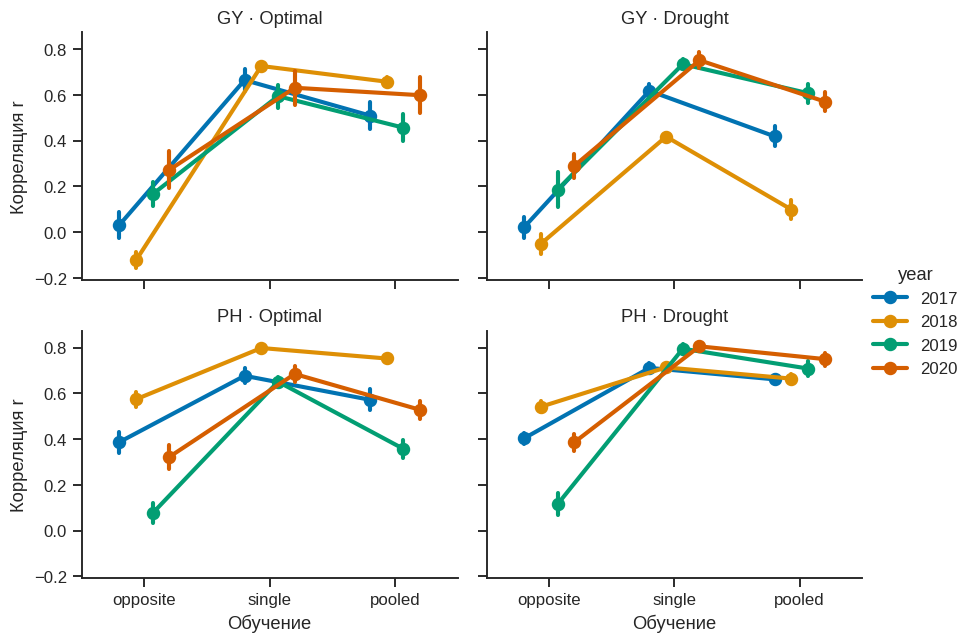

In [140]:
# T03/T10
from IPython.display import Image
display(Image(filename=str(OUT/'figures/BD_regimes.png')))

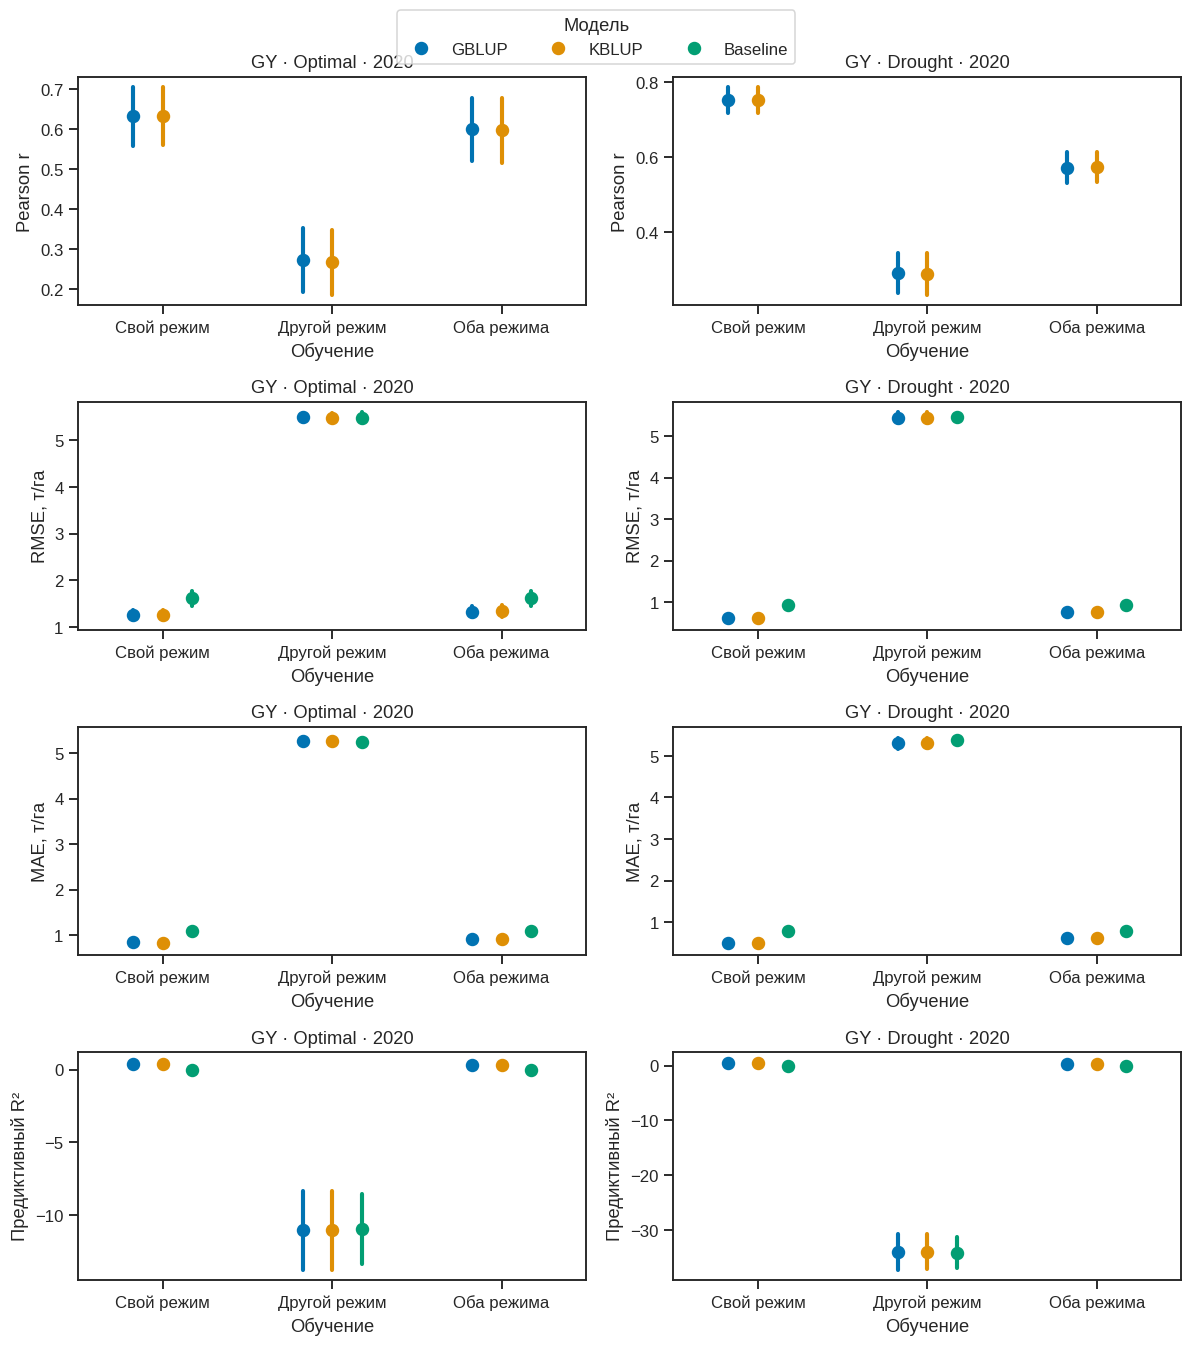

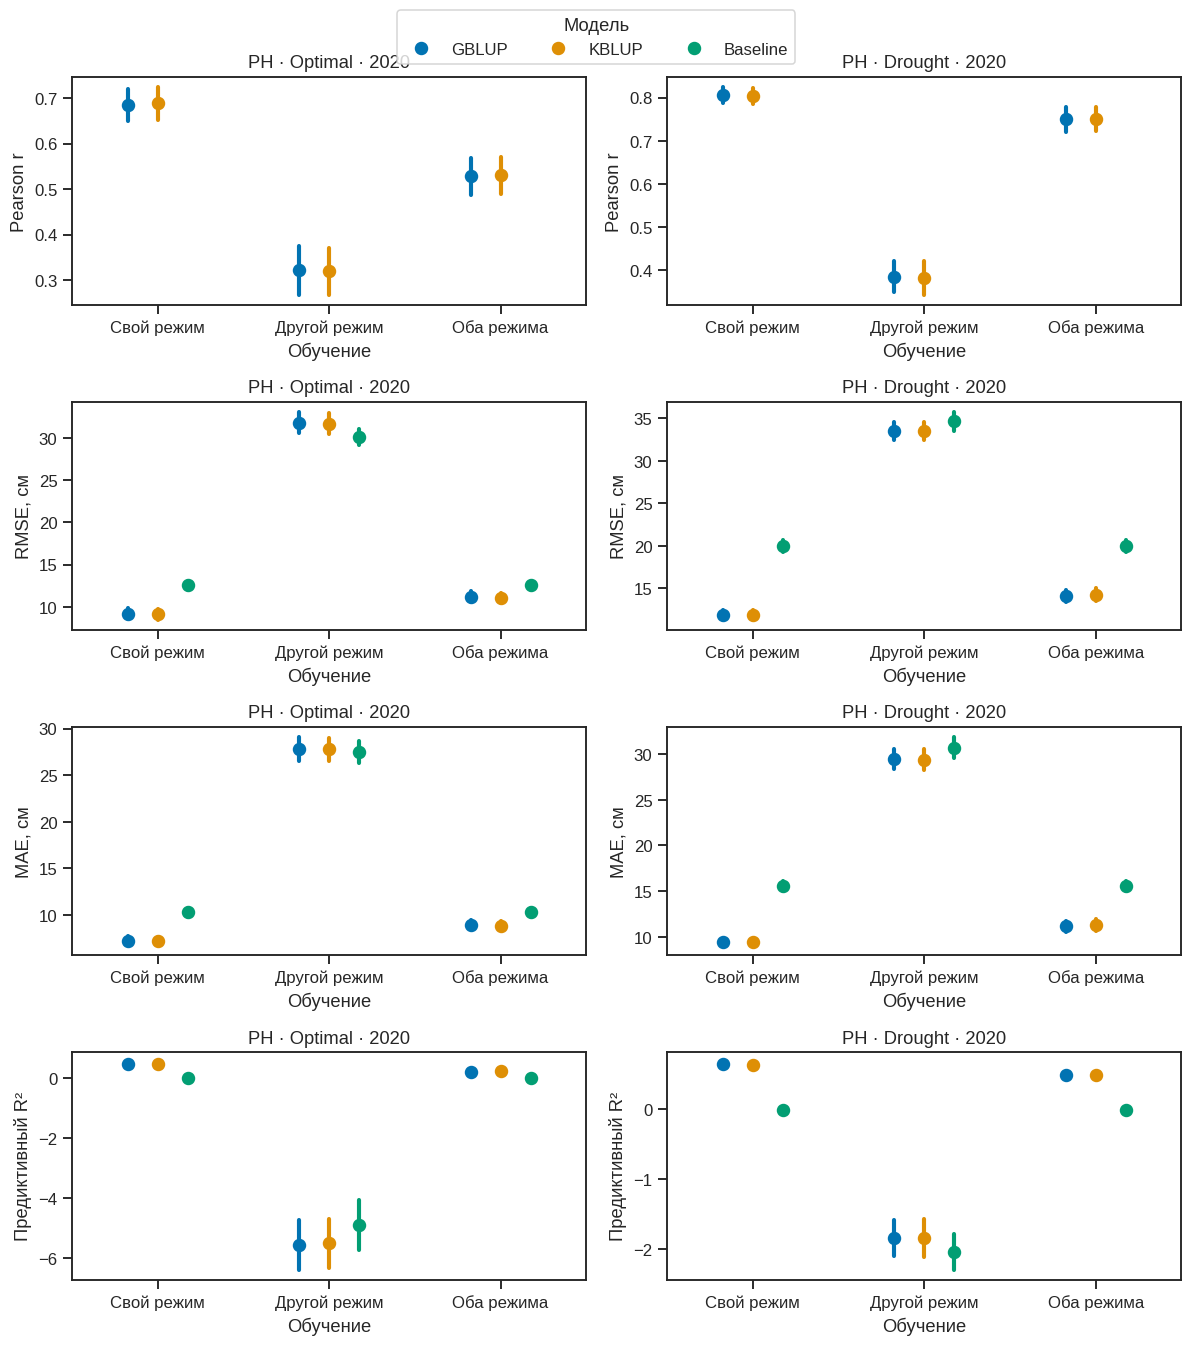

delta_r  delta_rmse  delta_mae  delta_r2
trait condition model                                          
GY    Drought   GBLUP   -0.206       0.127      0.115    -0.250
                KBLUP   -0.216       0.130      0.119    -0.253
      Optimal   GBLUP   -0.098       0.108      0.096    -0.152
                KBLUP   -0.104       0.121      0.108    -0.169
PH    Drought   GBLUP   -0.060       1.602      1.268    -0.129
                KBLUP   -0.065       1.769      1.422    -0.144
      Optimal   GBLUP   -0.150       1.710      1.519    -0.213
                KBLUP   -0.160       1.803      1.603    -0.217

### Что даёт сравнение трёх сценариев — T03/T10

single: те же train-GID измерены в целевом режиме. opposite: train-GID те же, но фенотипы взяты из другого режима. pooled: оба режима для тех же train-GID плюс фиксированный эффект режима. Test-GID и его целевой фенотип во всех трёх вариантах совпадают.

Панели четырёх метрик выше показывают 2020 год; предшествующий обзор и полная таблица включают все четыре года. Полосы — SD десяти согласованных разбиений. Положительная Δr pooled−single лучше; отрицательные ΔRMSE/ΔMAE лучше.

В таблице можно увидеть, что добавление записей второго режима не гарантирует улучшения. Модель pooled предполагает общий генетический компонент и сдвиг среднего режима; она не разрешает каждой линии собственную реакцию на засуху, то есть не является полноценной G×E-моделью.

Большая RMSE при opposite может сочетать плохое ранжирование и сдвиг среднего между режимами. Изменение r проверяет только линейную связь и не исправляет этот сдвиг.

Здесь сравниваются GBLUP, KBLUP и baseline. Лес, BRR и BayesA испытаны в A, но не во всех трёх сценариях. Кроме того, A использует все доступные фенотипы своей группы, B/D — только парно полные GID. Поэтому для строгого тройного сравнения берём single из D, а не подставляем результаты A.

In [155]:
# maize07_explained_v2: BD_four_metrics
# T03/T10: используем согласованные single/opposite/pooled, не смешиваем с A.
BD_all=pd.DataFrame(metrics_rows).query("stage in ['B','D']").copy()
scenario_order=['single','opposite','pooled']
for trait in TRAITS:
    unit='т/га' if trait=='GY' else 'см'
    fig,axes=plt.subplots(4,2,figsize=(11,12))
    for row,metric in enumerate(['r','rmse','mae','r2']):
        for column,condition in enumerate(CONDITIONS):
            ax=axes[row,column]
            d=BD_all.query('trait == @trait and condition == @condition and year == 2020')
            sns.pointplot(data=d,x='scenario',y=metric,hue='model',order=scenario_order,hue_order=['GBLUP','KBLUP','Baseline'],errorbar='sd',dodge=.35,palette='colorblind',linestyles='none',ax=ax)
            ax.set(title=f'{trait} · {condition} · 2020',xlabel='Обучение',ylabel=metric_names[metric]+(f', {unit}' if metric in ['rmse','mae'] else ''))
            ax.set_xticks(range(3),['Свой режим','Другой режим','Оба режима'])
            if row==0 and column==0: handles,labels=ax.get_legend_handles_labels()
            if ax.get_legend() is not None: ax.get_legend().remove()
    fig.legend(handles,labels,title='Модель',loc='upper center',ncol=3,bbox_to_anchor=(.5,1.025))
    show_explained_figure(fig,f'BD_four_metrics_2020_{trait}')
paired_BD=BD_all.pivot(index=['trait','condition','year','repeat','model'],columns='scenario',values=['r','rmse','mae','r2'])
paired_BD_delta=pd.DataFrame(index=paired_BD.index)
for metric in ['r','rmse','mae','r2']:
    paired_BD_delta[f'delta_{metric}']=paired_BD[(metric,'pooled')]-paired_BD[(metric,'single')]
summary_BD_delta=paired_BD_delta.reset_index().query("model != 'Baseline'").groupby(['trait','condition','model'])[['delta_r','delta_rmse','delta_mae','delta_r2']].mean()
display(summary_BD_delta.round(3))
explain_result('Что даёт сравнение трёх сценариев — T03/T10',[
    'single: те же train-GID измерены в целевом режиме. opposite: train-GID те же, но фенотипы взяты из другого режима. pooled: оба режима для тех же train-GID плюс фиксированный эффект режима. Test-GID и его целевой фенотип во всех трёх вариантах совпадают.',
    'Панели четырёх метрик выше показывают 2020 год; предшествующий обзор и полная таблица включают все четыре года. Полосы — SD десяти согласованных разбиений. Положительная Δr pooled−single лучше; отрицательные ΔRMSE/ΔMAE лучше.',
    'В таблице можно увидеть, что добавление записей второго режима не гарантирует улучшения. Модель pooled предполагает общий генетический компонент и сдвиг среднего режима; она не разрешает каждой линии собственную реакцию на засуху, то есть не является полноценной G×E-моделью.',
    'Большая RMSE при opposite может сочетать плохое ранжирование и сдвиг среднего между режимами. Изменение r проверяет только линейную связь и не исправляет этот сдвиг.',
    'Здесь сравниваются GBLUP, KBLUP и baseline. Лес, BRR и BayesA испытаны в A, но не во всех трёх сценариях. Кроме того, A использует все доступные фенотипы своей группы, B/D — только парно полные GID. Поэтому для строгого тройного сравнения берём single из D, а не подставляем результаты A.'
])

## C. Перенос между годами

Обучаем на каждом отдельном другом году (12 направлений) и на всех трёх остальных годах (LOYO). Для LOYO включён фиксированный эффект обучающих лет; неизвестный целевой год получает нулевые контрасты. Это не исправляет неизвестный сдвиг среднего target.

Сначала оцениваем **полный target**, затем те же новые прогнозы на 10 одинаковых для моделей 85%-подвыборках target. Последние не означают 10 переобучений или независимых опытов. Направления из будущего в прошлое — исследовательские сравнения, а не прогноз будущего.

In [124]:
# T03/T07/T10
for target_year in YEARS:
    started=time.perf_counter()
    sources = [(str(y),[y]) for y in YEARS if y!=target_year]+[('LOYO',[y for y in YEARS if y!=target_year])]
    for condition,trait,(source,train_years) in product(CONDITIONS,TRAITS,sources):
        train = records(train_years,trait,condition)
        target = records(target_year,trait,condition)
        result = train_case(train,target,KERNEL_MODELS,dict(stage='C',trait=trait,condition=condition,year=target_year,repeat=0,scenario=source,train_years='+'.join(map(str,train_years)),resample='full_target'))
        record_case(result)
        for repeat in CONFIG['seeds']:
            take = np.random.default_rng(repeat).permutation(len(target))[:round(CONFIG['target_fraction']*len(target))]
            record_case(result,subset=take,extra=dict(repeat=repeat,resample='target85'))
    save_stage(f'C_{target_year}',started)

C_2017: 410,928 новых прогнозов; метрик всего 2,928; 0.6 мин; расчёт суммарно 72.6 мин.


C_2018: 646,464 новых прогнозов; метрик всего 3,456; 0.4 мин; расчёт суммарно 73.1 мин.


C_2019: 329,112 новых прогнозов; метрик всего 3,984; 0.6 мин; расчёт суммарно 73.7 мин.


C_2020: 221,568 новых прогнозов; метрик всего 4,512; 0.7 мин; расчёт суммарно 74.4 мин.


In [125]:
# T03/T07/T10
C=pd.DataFrame(metrics_rows).query("stage == 'C'")
C_full=C.query("resample == 'full_target'")
C_full.to_csv(OUT/'C_full_target_metrics.csv',index=False)
C_summary=C.query("resample == 'target85'").groupby(['trait','condition','year','scenario','model'])[['r','rmse','mae','r2']].agg(['mean','std'])
C_summary.to_csv(OUT/'C_target85_summary.csv')
fig,axes=plt.subplots(2,2,figsize=(10,7))
for ax,(trait,condition) in zip(axes.flat,product(TRAITS,CONDITIONS)):
    d=C_full.query("trait == @trait and condition == @condition and model == 'GBLUP'")
    mat=d.pivot(index='scenario',columns='year',values='r').reindex(index=['2017','2018','2019','2020','LOYO'],columns=YEARS)
    sns.heatmap(mat,vmin=-1,vmax=1,cmap='vlag',annot=True,fmt='.2f',ax=ax,cbar_kws={'label':'r'})
    ax.set(title=f'{trait} · {condition}',xlabel='Целевой год',ylabel='Обучающий год')
fig.tight_layout()
for ext in ['png','svg']: fig.savefig(OUT/f'figures/C_year_transfer.{ext}',bbox_inches='tight')
plt.show()
display(C_full.query("year == 2020 and scenario == 'LOYO'")[['trait','condition','model','r','rmse','mae','r2']].round(3))
print('SD в C_target85_summary — чувствительность к составу target, а не изменчивость переобучения.')

,trait,condition,model,r,rmse,mae,r2
4083,GY,Optimal,GBLUP,0.128,1.937,1.259,-0.334
4084,GY,Optimal,KBLUP,0.104,1.904,1.240,-0.290
4085,GY,Optimal,Baseline,NaN,1.761,1.153,-0.103
4215,PH,Optimal,GBLUP,-0.014,21.112,17.983,-1.845
4216,PH,Optimal,KBLUP,0.047,20.363,17.154,-1.647
4217,PH,Optimal,Baseline,NaN,22.120,18.813,-2.123
4347,GY,Drought,GBLUP,-0.073,1.250,1.053,-0.861
4348,GY,Drought,KBLUP,-0.022,1.217,1.029,-0.763
4349,GY,Drought,Baseline,NaN,1.150,0.949,-0.575
4479,PH,Drought,GBLUP,0.022,23.823,19.942,-0.465


SD в C_target85_summary — чувствительность к составу target, а не изменчивость переобучения.


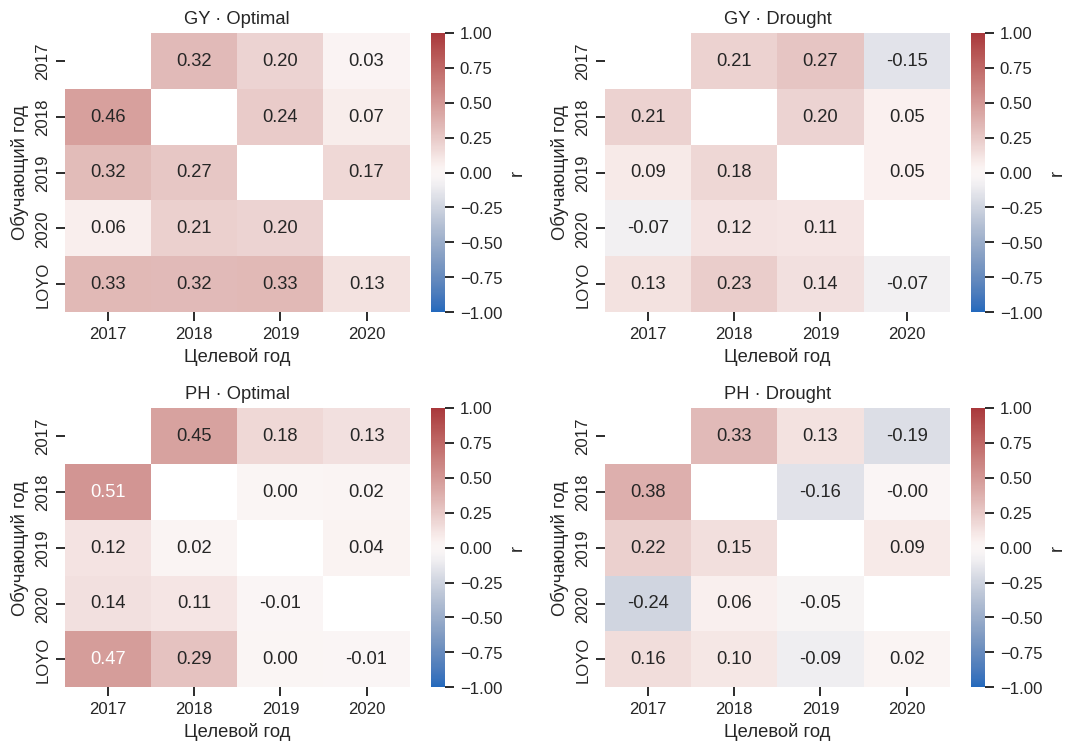

In [141]:
# T03/T07/T10
from IPython.display import Image
display(Image(filename=str(OUT/'figures/C_year_transfer.png')))

In [156]:
# maize07_explained_v2: C_interpretation
# T10: десять подвыборок target — не десять переобучений.
C_latest=pd.DataFrame(metrics_rows).query("stage == 'C'")
C_transfer=C_latest.query("year == 2020 and scenario == 'LOYO' and resample == 'full_target'")
display(C_transfer[['trait','condition','model','r','rmse','mae','r2']].round(3))
negative=int((C_transfer.r2<0).sum())
explain_result('Почему перенос года труднее обычного split — T10',[
    'В A train и test принадлежат одной когорте/году. В C целевой год полностью исключён из обучения; меняется и генетическая когорта, и уровень фенотипа. Поэтому высокая r внутри года не обещает такую же точность на новом году.',
    f"В показанном LOYO-прогнозе 2020 отрицательный предиктивный R² получен в {negative} из {len(C_transfer)} строк, включая baseline. Это реальный результат проверки, а не значение, которое нужно обрезать до нуля. Для выводов сравнивайте геномную модель с baseline внутри того же признака/режима.",
    'Фиксированные эффекты обучающих лет не позволяют узнать средний уровень неизвестного года: его контрасты равны нулю. Нельзя исправлять прогноз, используя наблюдённое среднее test.',
    'В каждой комбинации источника и target модель обучается на полном фиксированном train один раз. Полный target даёт основную оценку, а десять 85%-подвыборок проверяют чувствительность к составу target. Их SD не измеряет изменчивость повторного обучения.',
    'Направления из позднего года в ранний — исследовательские переносы, не прогноз будущего. Ни один опыт здесь не разделяет чистое влияние погоды и смены генетической когорты.'
])

,trait,condition,model,r,rmse,mae,r2
4083,GY,Optimal,GBLUP,0.128,1.937,1.259,-0.334
4084,GY,Optimal,KBLUP,0.104,1.904,1.240,-0.290
4085,GY,Optimal,Baseline,NaN,1.761,1.153,-0.103
4215,PH,Optimal,GBLUP,-0.014,21.112,17.983,-1.845
4216,PH,Optimal,KBLUP,0.047,20.363,17.154,-1.647
4217,PH,Optimal,Baseline,NaN,22.120,18.813,-2.123
4347,GY,Drought,GBLUP,-0.073,1.250,1.053,-0.861
4348,GY,Drought,KBLUP,-0.022,1.217,1.029,-0.763
4349,GY,Drought,Baseline,NaN,1.150,0.949,-0.575
4479,PH,Drought,GBLUP,0.022,23.823,19.942,-0.465


### Почему перенос года труднее обычного split — T10

В A train и test принадлежат одной когорте/году. В C целевой год полностью исключён из обучения; меняется и генетическая когорта, и уровень фенотипа. Поэтому высокая r внутри года не обещает такую же точность на новом году.

В показанном LOYO-прогнозе 2020 отрицательный предиктивный R² получен в 12 из 12 строк, включая baseline. Это реальный результат проверки, а не значение, которое нужно обрезать до нуля. Для выводов сравнивайте геномную модель с baseline внутри того же признака/режима.

Фиксированные эффекты обучающих лет не позволяют узнать средний уровень неизвестного года: его контрасты равны нулю. Нельзя исправлять прогноз, используя наблюдённое среднее test.

В каждой комбинации источника и target модель обучается на полном фиксированном train один раз. Полный target даёт основную оценку, а десять 85%-подвыборок проверяют чувствительность к составу target. Их SD не измеряет изменчивость повторного обучения.

Направления из позднего года в ранний — исследовательские переносы, не прогноз будущего. Ни один опыт здесь не разделяет чистое влияние погоды и смены генетической когорты.

## E. Помогают ли 73 локальные линии?

Для GY Optimal в 2020 году каждое разбиение оставляет **413 GID в test и 73 в резерве**. Test внутри повтора один и тот же для пяти источников: 2017; 2018; 2019; 2018+2019; 2017+2018+2019. Сравниваем обучение без локальных линий и с добавлением всех 73 резервных. Локальные фенотипы разрешены только во втором варианте. Это 10-повторный опыт, а не точное воспроизведение всех настроек исходной статьи.

Здесь **локальная** означает принадлежность целевой когорте, не географическое происхождение.
Код явно отделяет test от reserve; никакие фенотипы 413 test-GID не используются для оценки параметров.
Пять источников позволяют спросить, всегда ли добавление исторических лет полезно; baseline помогает отличить часть сдвига среднего от маркерной информации.


In [126]:
# T05/T08/T10
started=time.perf_counter()
sources_E = [[2017],[2018],[2019],[2018,2019],[2017,2018,2019]]
local_panel=records(2020,'GY','Optimal')
assert len(local_panel)==486
E_test_ids={}
for repeat in CONFIG['seeds']:
    order=np.random.default_rng(repeat).permutation(len(local_panel))
    target,reserve=local_panel.iloc[order[:413]],local_panel.iloc[order[413:]]
    assert len(target)==413 and len(reserve)==73
    E_test_ids[repeat]=set(target.GID)
    for source,local_n in product(sources_E,[0,73]):
        train=records(source,'GY','Optimal')
        if local_n: train=pd.concat([train,reserve],ignore_index=True)
        name='+'.join(map(str,source))
        result=train_case(train,target,KERNEL_MODELS,dict(stage='E',trait='GY',condition='Optimal',year=2020,repeat=repeat,scenario=f'{name}_local{local_n}',source=name,local_n=local_n,resample='split'))
        assert set(result['target'].GID)==E_test_ids[repeat]
        record_case(result)
    print(f'E: повтор {repeat}/10',flush=True)
save_stage('E',started)

E: повтор 1/10


E: повтор 2/10


E: повтор 3/10


E: повтор 4/10


E: повтор 5/10


E: повтор 6/10


E: повтор 7/10


E: повтор 8/10


E: повтор 9/10


E: повтор 10/10


E: 123,900 новых прогнозов; метрик всего 4,812; 4.7 мин; расчёт суммарно 79.2 мин.


In [127]:
# T05/T08/T10
E=pd.DataFrame(metrics_rows).query("stage == 'E'")
E_summary=E.groupby(['source','local_n','model'])[['r','rmse','mae','r2']].agg(['mean','std'])
E_summary.to_csv(OUT/'E_summary.csv')
display(E_summary.round(3))
fig,axes=plt.subplots(1,2,figsize=(11,4))
for ax,metric,label in zip(axes,['r','rmse'],['Корреляция r','RMSE, т/га']):
    sns.pointplot(data=E.query("model == 'GBLUP'"),x='source',y=metric,hue='local_n',errorbar='sd',dodge=.3,ax=ax,palette='colorblind')
    ax.set(xlabel='Источник обучения',ylabel=label)
    ax.tick_params(axis='x',rotation=15)
    ax.legend(title='Локальных линий')
fig.tight_layout()
for ext in ['png','svg']: fig.savefig(OUT/f'figures/E_local_lines.{ext}',bbox_inches='tight')
plt.show()
print('SD здесь обусловлена разными 413 test и 73 резервными GID; при local0 обучение фиксировано внутри каждого источника.')

r          rmse           mae         \
                                  mean    std   mean    std   mean    std   
source         local_n model                                                
2017           0.0     Baseline    NaN    NaN  2.295  0.063  1.700  0.026   
                       GBLUP     0.027  0.024  2.560  0.063  1.972  0.028   
                       KBLUP     0.048  0.023  2.534  0.063  1.954  0.027   
               73.0    Baseline    NaN    NaN  1.686  0.068  1.121  0.025   
                       GBLUP     0.582  0.084  1.405  0.138  0.911  0.044   
                       KBLUP     0.590  0.078  1.395  0.137  0.902  0.044   
2017+2018+2019 0.0     Baseline    NaN    NaN  1.764  0.069  1.155  0.032   
                       GBLUP     0.127  0.012  1.942  0.071  1.264  0.035   
                       KBLUP     0.104  0.013  1.909  0.071  1.246  0.035   
               73.0    Baseline    NaN    NaN  1.686  0.068  1.121  0.025   
                       GBLUP     0.483  0.090  1.481  0.128  0.979  0.042   
                       KBLUP     0.530  0.084  1.443  0.134  0.948  0.046   
2018           0.0     Baseline    NaN    NaN  1.736  0.057  1.237  0.030   
                       GBLUP     0.070  0.013  1.731  0.058  1.218  0.030   
                       KBLUP     0.109  0.013  1.691  0.060  1.169  0.030   
               73.0    Baseline    NaN    NaN  1.686  0.068  1.121  0.025   
                       GBLUP     0.533  0.068  1.442  0.116  0.974  0.036   
                       KBLUP     0.565  0.061  1.414  0.122  0.937  0.038   
2018+2019      0.0     Baseline    NaN    NaN  1.682  0.066  1.111  0.033   
                       GBLUP     0.142  0.013  1.773  0.071  1.151  0.036   
                       KBLUP     0.112  0.014  1.748  0.071  1.128  0.036   
               73.0    Baseline    NaN    NaN  1.686  0.068  1.121  0.025   
                       GBLUP     0.511  0.084  1.457  0.127  0.979  0.041   
                       KBLUP     0.543  0.079  1.430  0.133  0.948  0.043   
2019           0.0     Baseline    NaN    NaN  2.075  0.066  1.464  0.028   
                       GBLUP     0.174  0.013  2.211  0.068  1.590  0.031   
                       KBLUP     0.145  0.014  2.189  0.069  1.565  0.031   
               73.0    Baseline    NaN    NaN  1.686  0.068  1.121  0.025   
                       GBLUP     0.547  0.080  1.424  0.126  0.944  0.042   
                       KBLUP     0.564  0.078  1.411  0.135  0.926  0.047   

                                    r2         
                                  mean    std  
source         local_n model                   
2017           0.0     Baseline -0.874  0.045  
                       GBLUP    -1.331  0.072  
                       KBLUP    -1.285  0.069  
               73.0    Baseline -0.010  0.008  
                       GBLUP     0.299  0.091  
                       KBLUP     0.309  0.089  
2017+2018+2019 0.0     Baseline -0.106  0.004  
                       GBLUP    -0.340  0.012  
                       KBLUP    -0.296  0.010  
               73.0    Baseline -0.010  0.008  
                       GBLUP     0.221  0.082  
                       KBLUP     0.260  0.086  
2018           0.0     Baseline -0.071  0.013  
                       GBLUP    -0.066  0.013  
                       KBLUP    -0.017  0.009  
               73.0    Baseline -0.010  0.008  
                       GBLUP     0.262  0.070  
                       KBLUP     0.290  0.074  
2018+2019      0.0     Baseline -0.005  0.002  
                       GBLUP    -0.117  0.010  
                       KBLUP    -0.086  0.008  
               73.0    Baseline -0.010  0.008  
                       GBLUP     0.246  0.080  
                       KBLUP     0.273  0.085  
2019           0.0     Baseline -0.531  0.024  
                       GBLUP    -0.738  0.031  
                       KBLUP    -0.703  0.029  
               73.0    Baseline -0.010  0.008  
       

SD здесь обусловлена разными 413 test и 73 резервными GID; при local0 обучение фиксировано внутри каждого источника.


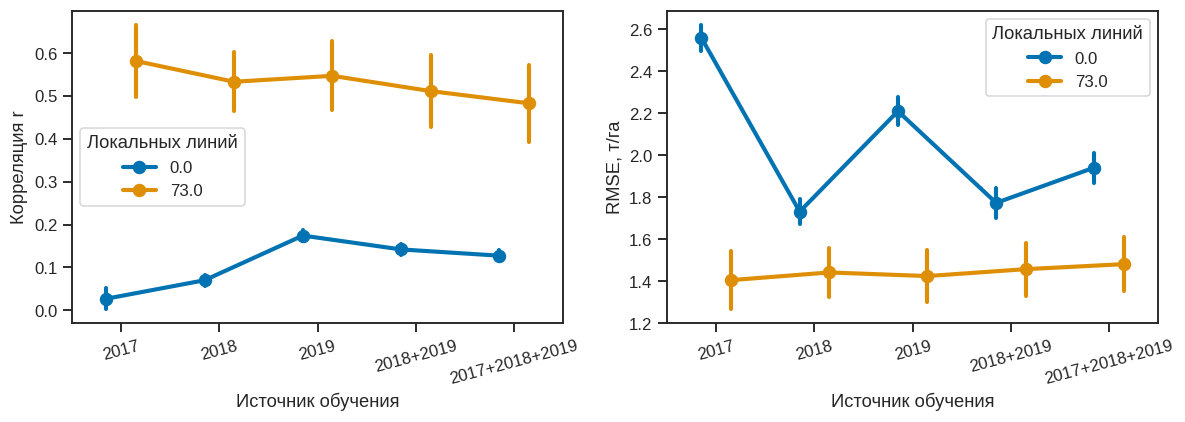

In [142]:
# T05/T08/T10
from IPython.display import Image
display(Image(filename=str(OUT/'figures/E_local_lines.png')))

In [157]:
# maize07_explained_v2: local_lines_interpretation
# T08/T10: локальные = линии целевого цикла с разрешёнными обучающими фенотипами.
E_latest=pd.DataFrame(metrics_rows).query("stage == 'E'")
E_means=E_latest.groupby(['source','local_n','model'])[['r','rmse','mae','r2']].mean().reset_index()
local_source=E_means.query("source == '2017+2018+2019' and model == 'GBLUP'").set_index('local_n')
local_baseline=E_means.query("source == '2017+2018+2019' and model == 'Baseline'").set_index('local_n')
explain_result('Локальные линии на конкретном примере — T08/T10',[
    '**Локальные линии — это линии того цикла, для которого нужен прогноз.** В данном опыте это 2020 год; слово не означает географически местные сорта. Если у 73 из 486 линий уже есть измеренная GY, их можно использовать для обучения. Остальные 413 имеют скрытые для обучения фенотипы и составляют test.',
    'Без локальных линий: train = 3041 линия 2017–2019; test = 413 линий 2020; оставшиеся 73 не используются. С локальными: train = 3041+73 = 3114; test — те же самые 413. Нельзя включать в train фенотипы этих 413 GID.',
    f"Для GBLUP с источником 2017–2019 добавление 73 линий меняет среднюю r с {local_source.loc[0,'r']:.3f} до {local_source.loc[73,'r']:.3f}, RMSE — с {local_source.loc[0,'rmse']:.3f} до {local_source.loc[73,'rmse']:.3f} т/га.",
    f"При этом RMSE baseline тоже меняется: {local_baseline.loc[0,'rmse']:.3f} → {local_baseline.loc[73,'rmse']:.3f} т/га. Значит, часть пользы — возможность оценить уровень целевого года, а не только генетическая близость. Нельзя приписать весь выигрыш одному механизму.",
    'Опыт E специально повторяет основной вопрос статьи для GY Optimal. Основные сравнения A/B/C/D/F/G выполнены также для PH, но дополнительный опыт E не объявляется двухпризначной полной репликацией статьи. SD в E отражает разные 413 test и 73 резервных GID.'
])

### Локальные линии на конкретном примере — T08/T10

**Локальные линии — это линии того цикла, для которого нужен прогноз.** В данном опыте это 2020 год; слово не означает географически местные сорта. Если у 73 из 486 линий уже есть измеренная GY, их можно использовать для обучения. Остальные 413 имеют скрытые для обучения фенотипы и составляют test.

Без локальных линий: train = 3041 линия 2017–2019; test = 413 линий 2020; оставшиеся 73 не используются. С локальными: train = 3041+73 = 3114; test — те же самые 413. Нельзя включать в train фенотипы этих 413 GID.

Для GBLUP с источником 2017–2019 добавление 73 линий меняет среднюю r с 0.127 до 0.483, RMSE — с 1.942 до 1.481 т/га.

При этом RMSE baseline тоже меняется: 1.764 → 1.686 т/га. Значит, часть пользы — возможность оценить уровень целевого года, а не только генетическая близость. Нельзя приписать весь выигрыш одному механизму.

Опыт E специально повторяет основной вопрос статьи для GY Optimal. Основные сравнения A/B/C/D/F/G выполнены также для PH, но дополнительный опыт E не объявляется двухпризначной полной репликацией статьи. SD в E отражает разные 413 test и 73 резервных GID.

<a id="tz-T08"></a>
## Что проверено относительно исходной статьи — T08

Lopez-Cruz et al. (2021), *Multi-generation genomic prediction of maize yield using parametric and non-parametric sparse selection indices*,
рассматривали перенос урожайности между когортами и включение данных целевого поколения. [1](https://www.nature.com/articles/s41437-021-00474-1)

| Компонент | В статье | Здесь |
|---|---|---|
| Линейный GBLUP | Стандартизация каждого маркера, Bayesian-оценка дисперсий BGLR | Центрирование train и общая нормировка ядра, REML |
| Нелинейное ядро | Gaussian с тремя ширинами и их взвешенной комбинацией | Одно Gaussian-ядро с медианной обучающей шириной |
| GSSI/KSSI | L1-разреженные индексы: индивидуальный набор поддержки для каждой предсказываемой линии; внутренняя CV настройки | **Не реализованы**; общий nearest/farthest панели не эквивалентен SSI |
| Локальные данные 2020 | 100 разбиений, 413 test, варианты 0/25/49/73 локальных линий | 10 разбиений, 413 test, варианты 0/73; только GY Optimal |
| Главная мера качества | Корреляция наблюдений и прогнозов | Та же r плюс RMSE, MAE и предиктивный R² |

Методы и настройки статьи: [1](https://www.nature.com/articles/s41437-021-00474-1).
Следующая ячейка сопоставляет **GBLUP** при +73 локальных линиях, а не подменяет его лучшими SSI-результатами.
Числа статьи — Table 2, строки G, столбец BLUP; наши числа вычисляются из E. [2](https://www.nature.com/articles/s41437-021-00474-1/tables/2)

Смысл сравнения — проверить согласованность наблюдений о переносе и локальных данных, **не** объявить новую модель лучше опубликованной по несогласованным повторным разбиениям.

In [163]:
# maize07_explained_v2: article_comparison
# T08: числа статьи — Table 2, G / BLUP; наши — только новый полный прогон.
# [1] https://www.nature.com/articles/s41437-021-00474-1
# [2] https://www.nature.com/articles/s41437-021-00474-1/tables/2
published_73=pd.DataFrame({'source':['2017','2018','2019','2018+2019','2017+2018+2019'],
                          'article_r':[.54,.52,.51,.48,.43],
                          'article_sd':[.079,.064,.068,.071,.079]})
our_73=pd.DataFrame(metrics_rows).query("stage == 'E' and model == 'GBLUP' and local_n == 73").groupby('source').agg(our_r=('r','mean'),our_sd=('r','std'),our_rmse=('rmse','mean'),n_repeats=('repeat','nunique')).reset_index()
article_comparison=published_73.merge(our_73,on='source',validate='one_to_one')
assert len(article_comparison)==5 and article_comparison.n_repeats.eq(10).all()
article_comparison.to_csv(OUT/'article_Table2_GBLUP_comparison.csv',index=False)
display(article_comparison.round(3))
our_no_local=pd.DataFrame(metrics_rows).query("stage == 'E' and model == 'GBLUP' and local_n == 0").groupby('source').r.mean()
explain_result('Сопоставление со статьёй — T08',[
    'Таблица выше: **GY Optimal 2020**, train из указанных прошлых лет +73 локальные линии, test=413. Опубликованные r и SD взяты из Table 2, строк G и столбца BLUP, а не из столбца SSI. [2](https://www.nature.com/articles/s41437-021-00474-1/tables/2)',
    f"Без локальных линий для источника 2019 в статье r≈0,18, у нас {our_no_local.loc['2019']:.3f}; для источника 2017 — ≈0,02 и {our_no_local.loc['2017']:.3f}. Обе работы показывают слабый перенос без данных целевой когорты и сильное улучшение при их добавлении. [1](https://www.nature.com/articles/s41437-021-00474-1)",
    'Более высокие наши средние в таблице не доказывают превосходства: у авторов 100 разбиений, у нас 10; дисперсии у них оценены Bayesian/BGLR, у нас для GBLUP/KBLUP — REML. Авторы стандартизовали отдельные маркеры, а наша линейная матрица использует центрирование и общую обучающую шкалу. Различаются также фиксированные эффекты и настройка Gaussian-ядра. [1](https://www.nature.com/articles/s41437-021-00474-1)',
    'У авторов три ширины Gaussian-ядра и их взвешенная комбинация; у нас одно ядро с медианной обучающей шириной. **GSSI/KSSI не реализованы**: основной результат об индивидуальном разреженном наборе обучения мы не проверили. Общий nearest/farthest для всей панели не равен индивидуальному SSI. [1](https://www.nature.com/articles/s41437-021-00474-1)',
    'Сравнение статьи по r нельзя подменять сравнением r с нашим R². Анализ методов и выводов статьи выполнен, но точной репликацией всех её моделей и настроек этот ноутбук не является.'
])

,source,article_r,article_sd,our_r,our_sd,our_rmse,n_repeats
0,2017,0.54,0.079,0.582,0.084,1.405,10
1,2018,0.52,0.064,0.533,0.068,1.442,10
2,2019,0.51,0.068,0.547,0.080,1.424,10
3,2018+2019,0.48,0.071,0.511,0.084,1.457,10
4,2017+2018+2019,0.43,0.079,0.483,0.090,1.481,10


### Сопоставление со статьёй — T08

Таблица выше: **GY Optimal 2020**, train из указанных прошлых лет +73 локальные линии, test=413. Опубликованные r и SD взяты из Table 2, строк G и столбца BLUP, а не из столбца SSI. [2](https://www.nature.com/articles/s41437-021-00474-1/tables/2)

Без локальных линий для источника 2019 в статье r≈0,18, у нас 0.174; для источника 2017 — ≈0,02 и 0.027. Обе работы показывают слабый перенос без данных целевой когорты и сильное улучшение при их добавлении. [1](https://www.nature.com/articles/s41437-021-00474-1)

Более высокие наши средние в таблице не доказывают превосходства: у авторов 100 разбиений, у нас 10; дисперсии у них оценены Bayesian/BGLR, у нас для GBLUP/KBLUP — REML. Авторы стандартизовали отдельные маркеры, а наша линейная матрица использует центрирование и общую обучающую шкалу. Различаются также фиксированные эффекты и настройка Gaussian-ядра. [1](https://www.nature.com/articles/s41437-021-00474-1)

У авторов три ширины Gaussian-ядра и их взвешенная комбинация; у нас одно ядро с медианной обучающей шириной. **GSSI/KSSI не реализованы**: основной результат об индивидуальном разреженном наборе обучения мы не проверили. Общий nearest/farthest для всей панели не равен индивидуальному SSI. [1](https://www.nature.com/articles/s41437-021-00474-1)

Сравнение статьи по r нельзя подменять сравнением r с нашим R². Анализ методов и выводов статьи выполнен, но точной репликацией всех её моделей и настроек этот ноутбук не является.

<a id="tz-T05"></a>
## F. Размер и генетическая близость обучения

Из прошлых лет выбираем 250/500/1000/2000/все доступные линии: ближайшие, случайные или самые далёкие по **средней IBS к всей панели 2020**. Генотипы target используются, его фенотипы — нет. Это трансдуктивная схема: предполагается, что будущая генотипированная панель известна при выборе обучения.

Внутри повтора проверочные 85% GID одинаковы для всех стратегий/размеров. nearest/farthest меняют только состав проверочной подвыборки; random дополнительно меняет train. Для «все» модель обучается один раз и её новые прогнозы переиспользуются с явной маркировкой. Это не 30 независимых обучений.

In [128]:
# T05/T11/T10
requested_sizes=[250,500,1000,2000,'all']
for trait,condition in product(TRAITS,CONDITIONS):
    started=time.perf_counter()
    candidates=records([2017,2018,2019],trait,condition).reset_index(drop=True)
    target=records(2020,trait,condition).reset_index(drop=True)
    target_panel_rows=pheno.loc[pheno.Year==2020,'row'].to_numpy()
    similarity=ibs[np.ix_(candidates.row.to_numpy(),target_panel_rows)].mean(axis=1)
    ranks={'nearest':np.argsort(-similarity,kind='stable'),'farthest':np.argsort(similarity,kind='stable')}
    fixed_results={}
    F_test_sets={repeat:np.random.default_rng(repeat).permutation(len(target))[:round(CONFIG['target_fraction']*len(target))] for repeat in CONFIG['seeds']}
    for requested in requested_sizes:
        n=len(candidates) if requested=='all' else min(int(requested),len(candidates))
        if requested=='all':
            fitted_all=train_case(candidates,target,['GBLUP','Baseline'],dict(stage='F',trait=trait,condition=condition,year=2020,repeat=0,scenario='all',selection='all',requested_n='all',resample='target85'))
        for selection in ['nearest','random','farthest']:
            if requested!='all' and selection!='random':
                train=candidates.iloc[ranks[selection][:n]]
                fitted_fixed=train_case(train,target,['GBLUP','Baseline'],dict(stage='F',trait=trait,condition=condition,year=2020,repeat=0,scenario=f'{selection}_{requested}',selection=selection,requested_n=str(requested),resample='target85'))
            for repeat in CONFIG['seeds']:
                take=F_test_sets[repeat]
                if requested=='all':
                    result=fitted_all
                elif selection=='random':
                    choose=np.random.default_rng(1000+repeat).permutation(len(candidates))[:n]
                    result=train_case(candidates.iloc[choose],target,['GBLUP','Baseline'],dict(stage='F',trait=trait,condition=condition,year=2020,repeat=repeat,scenario=f'{selection}_{requested}',selection=selection,requested_n=str(requested),resample='target85'))
                else:
                    result=fitted_fixed
                record_case(result,subset=take,extra=dict(repeat=repeat,selection=selection,scenario=f'{selection}_{requested}',requested_n=str(requested)))
    save_stage(f'F_{trait}_{condition}',started)

F_GY_Optimal: 123,900 новых прогнозов; метрик всего 5,112; 0.4 мин; расчёт суммарно 79.6 мин.


F_GY_Drought: 123,900 новых прогнозов; метрик всего 5,412; 0.4 мин; расчёт суммарно 80.0 мин.


F_PH_Optimal: 123,900 новых прогнозов; метрик всего 5,712; 0.4 мин; расчёт суммарно 80.4 мин.


F_PH_Drought: 123,900 новых прогнозов; метрик всего 6,012; 0.4 мин; расчёт суммарно 80.8 мин.


In [129]:
# T05/T11/T10
F_metrics=pd.DataFrame(metrics_rows).query("stage == 'F'")
F_summary=F_metrics.groupby(['trait','condition','requested_n','selection','model'])[['r','rmse','mae','r2']].agg(['mean','std'])
F_summary.to_csv(OUT/'F_summary.csv')
g=sns.catplot(data=F_metrics.query("model == 'GBLUP'"),x='requested_n',y='r',hue='selection',row='trait',col='condition',order=list(map(str,requested_sizes)),kind='point',errorbar='sd',dodge=.25,height=3,aspect=1.4,palette='colorblind')
g.set_axis_labels('Линий в train','Корреляция r');g.set_titles('{row_name} · {col_name}')
for ext in ['png','svg']: g.figure.savefig(OUT/f'figures/F_training_selection.{ext}',bbox_inches='tight')
plt.show()
display(F_summary.round(3))
print('SD nearest/farthest: подвыборки target. SD random: меняются и train, и target. Сравнивать как одинаковые источники неопределённости нельзя.')

r           rmse         \
                                                 mean    std    mean    std   
trait condition requested_n selection model                                   
GY    Drought   1000        farthest  Baseline    NaN    NaN   1.193  0.011   
                                      GBLUP    -0.159  0.017   1.348  0.012   
                            nearest   Baseline    NaN    NaN   1.088  0.010   
                                      GBLUP    -0.024  0.011   1.188  0.009   
                            random    Baseline    NaN    NaN   1.155  0.021   
...                                               ...    ...     ...    ...   
PH    Optimal   all         farthest  GBLUP    -0.013  0.024  21.162  0.198   
                            nearest   Baseline    NaN    NaN  22.145  0.214   
                                      GBLUP    -0.013  0.024  21.162  0.198   
                            random    Baseline    NaN    NaN  22.145  0.214   
                                      GBLUP    -0.013  0.024  21.162  0.198   

                                                   mae            r2         
                                                  mean    std   mean    std  
trait condition requested_n selection model                                  
GY    Drought   1000        farthest  Baseline   0.984  0.012 -0.701  0.041  
                                      GBLUP      1.141  0.016 -1.171  0.059  
                            nearest   Baseline   0.900  0.011 -0.414  0.031  
                                      GBLUP      0.974  0.010 -0.686  0.036  
                            random    Baseline   0.953  0.018 -0.595  0.054  
...                                                ...    ...    ...    ...  
PH    Optimal   all         farthest  GBLUP     18.037  0.199 -1.858  0.048  
                            nearest   Baseline  18.827  0.229 -2.129  0.044  
                                      GBLUP     18.037  0.199 -1.858  0.048  
                            random    Baseline  18.827  0.229 -2.129  0.044  
                                      GBLUP     18.037  0.199 -1.858  0.048  

[120 rows x 8 columns]

SD nearest/farthest: подвыборки target. SD random: меняются и train, и target. Сравнивать как одинаковые источники неопределённости нельзя.


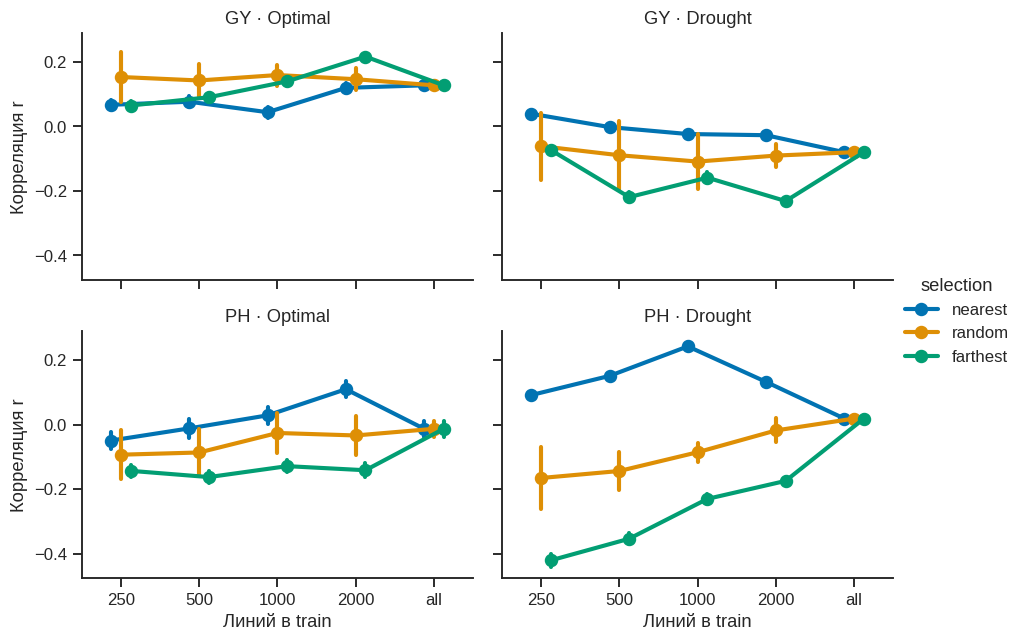

In [143]:
# T05/T11/T10
from IPython.display import Image
display(Image(filename=str(OUT/'figures/F_training_selection.png')))

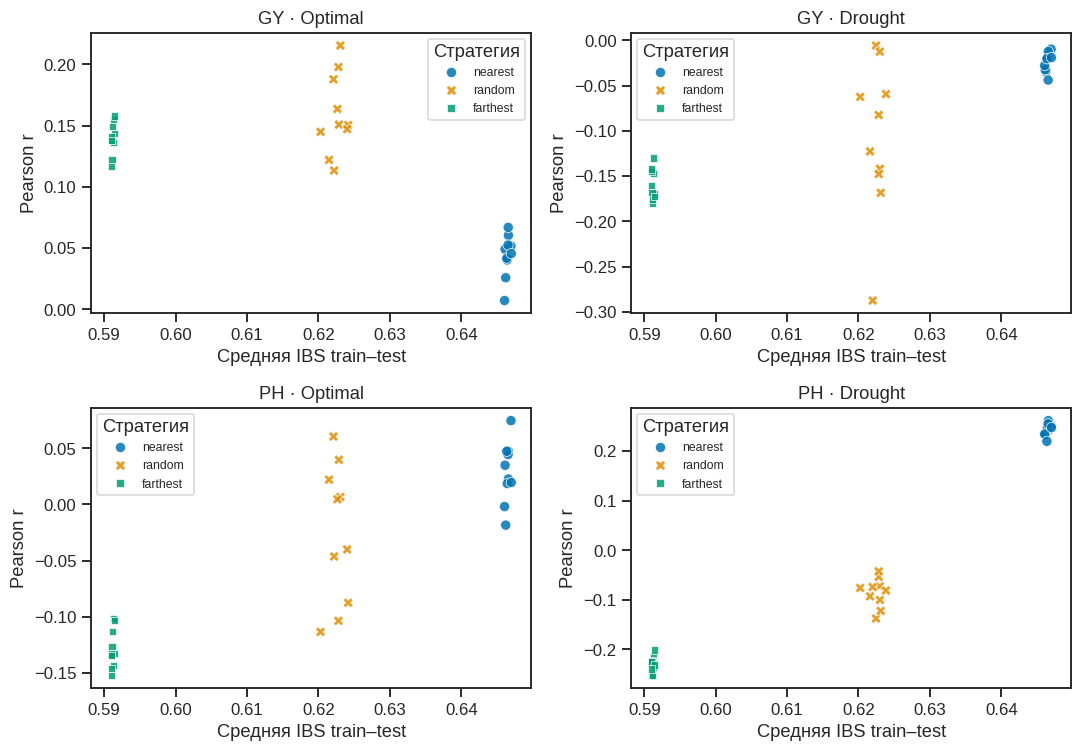

,trait,condition,selection,mean_ibs,r_mean,r_sd,rmse_mean
0,GY,Drought,farthest,0.5912,-0.1590,0.0169,1.3479
1,GY,Drought,nearest,0.6465,-0.0237,0.0107,1.1878
2,GY,Drought,random,0.6225,-0.1091,0.0840,1.2183
3,GY,Optimal,farthest,0.5912,0.1397,0.0129,1.9618
4,GY,Optimal,nearest,0.6465,0.0440,0.0172,2.0341
5,GY,Optimal,random,0.6226,0.1593,0.0325,1.8756
6,PH,Drought,farthest,0.5912,-0.2302,0.0161,25.3671
7,PH,Drought,nearest,0.6465,0.2428,0.0122,20.6928
8,PH,Drought,random,0.6225,-0.0855,0.0291,24.0259
9,PH,Optimal,farthest,0.5912,-0.1287,0.0176,20.1491


### Как оценивать влияние близости и размера — T05/T11

На новом scatter размер train заранее зафиксирован: 1000 линий. Это отделяет сравнение стратегий от тривиального различия в числе обучающих образцов. Средняя IBS вычислена именно между фактическими train и test каждого опыта, а не взята из названия nearest/farthest.

nearest/farthest выбирались по средней IBS к всей генотипированной панели 2020 без её фенотипов. Это трансдуктивный выбор: предполагается, что генотипы будущей панели уже известны. На рисунке — IBS к проверочной подвыборке, поэтому она немного меняется между повторами.

Генетическая близость может помогать, но не гарантирует хорошую r: остаются различия когорт, сред, фенотипического уровня и генетических эффектов. Смотрите на фактические значения по обоим признакам/режимам, а не только на положение групп по x.

У nearest/farthest фиксирован train, меняется 85% target; у random меняется и train. При «all» обучающая выборка одинакова у всех стратегий, поэтому совпадение результатов ожидаемо, а не три независимых подтверждения.

Точки и повторы зависимы, поэтому здесь нет причинной оценки эффекта IBS и нет p-value по этим 120 точкам. Весь диапазон размеров 250/500/1000/2000/all остаётся на предыдущем графике и в полной таблице F.

In [158]:
# maize07_explained_v2: actual_train_test_IBS
# T05/T11: фактическая IBS между уникальными train/test, без изменения моделей.
F_latest=pd.DataFrame(metrics_rows).query("stage == 'F' and model == 'GBLUP'").copy()
identity_keys=['case_id','trait','condition','year','repeat','scenario','resample','selection','requested_n']
F_latest['requested_n']=F_latest.requested_n.astype(str)
ibs_rows=[]
for trait,condition in product(TRAITS,CONDITIONS):
    path=OUT/f'manifest_F_{trait}_{condition}.parquet'
    manifest=pd.read_parquet(path,columns=identity_keys+['GID','row','role'])
    manifest['requested_n']=manifest.requested_n.astype(str)
    for identity,group in manifest.groupby(identity_keys,sort=False,dropna=False):
        train=group.loc[group.role=='train',['GID','row']].drop_duplicates('GID')
        test=group.loc[group.role=='test',['GID','row']].drop_duplicates('GID')
        assert not set(train.GID)&set(test.GID)
        for frame in [train,test]:
            np.testing.assert_array_equal(pheno.GID.to_numpy()[frame['row'].to_numpy(int)],frame.GID.to_numpy())
        train_rows=train['row'].to_numpy(int); test_rows=test['row'].to_numpy(int)
        mean_ibs=float(ibs[np.ix_(train_rows,test_rows)].mean(dtype=np.float64))
        assert 0<=mean_ibs<=1
        ibs_rows.append(dict(zip(identity_keys,identity),mean_ibs=mean_ibs,mean_hamming=1-mean_ibs,unique_train=len(train),unique_test=len(test)))
    del manifest
F_closeness=F_latest.merge(pd.DataFrame(ibs_rows),on=identity_keys,validate='one_to_one')
assert len(F_closeness)==600 and F_closeness.mean_ibs.notna().all()
F_closeness.to_csv(OUT/'F_train_test_ibs.csv',index=False)
F_1000=F_closeness.query("requested_n == '1000'").copy()
assert len(F_1000)==120 and F_1000.unique_train.eq(1000).all()
fig,axes=plt.subplots(2,2,figsize=(10,7))
for ax,(trait,condition) in zip(axes.flat,product(TRAITS,CONDITIONS)):
    d=F_1000.query('trait == @trait and condition == @condition')
    sns.scatterplot(data=d,x='mean_ibs',y='r',hue='selection',hue_order=['nearest','random','farthest'],style='selection',palette='colorblind',s=45,alpha=.85,ax=ax)
    ax.set(title=f'{trait} · {condition}',xlabel='Средняя IBS train–test',ylabel='Pearson r')
    ax.legend(title='Стратегия',fontsize=8)
show_explained_figure(fig,'F_actual_IBS_accuracy_n1000')
F_1000_summary=F_1000.groupby(['trait','condition','selection']).agg(mean_ibs=('mean_ibs','mean'),r_mean=('r','mean'),r_sd=('r','std'),rmse_mean=('rmse','mean')).reset_index()
F_1000_summary.to_csv(OUT/'F_IBS_n1000_summary.csv',index=False)
display(F_1000_summary.round(4))
explain_result('Как оценивать влияние близости и размера — T05/T11',[
    'На новом scatter размер train заранее зафиксирован: 1000 линий. Это отделяет сравнение стратегий от тривиального различия в числе обучающих образцов. Средняя IBS вычислена именно между фактическими train и test каждого опыта, а не взята из названия nearest/farthest.',
    'nearest/farthest выбирались по средней IBS к всей генотипированной панели 2020 без её фенотипов. Это трансдуктивный выбор: предполагается, что генотипы будущей панели уже известны. На рисунке — IBS к проверочной подвыборке, поэтому она немного меняется между повторами.',
    'Генетическая близость может помогать, но не гарантирует хорошую r: остаются различия когорт, сред, фенотипического уровня и генетических эффектов. Смотрите на фактические значения по обоим признакам/режимам, а не только на положение групп по x.',
    'У nearest/farthest фиксирован train, меняется 85% target; у random меняется и train. При «all» обучающая выборка одинакова у всех стратегий, поэтому совпадение результатов ожидаемо, а не три независимых подтверждения.',
    'Точки и повторы зависимы, поэтому здесь нет причинной оценки эффекта IBS и нет p-value по этим 120 точкам. Весь диапазон размеров 250/500/1000/2000/all остаётся на предыдущем графике и в полной таблице F.'
])

In [161]:
# maize07_explained_v2: F_specific_findings
# T05: интерпретация фактических результатов при одинаковом n_train=1000.
f_examples=F_1000_summary.set_index(['trait','condition','selection'])
near_gy=f_examples.loc[('GY','Optimal','nearest')]
random_gy=f_examples.loc[('GY','Optimal','random')]
far_ph=f_examples.loc[('PH','Drought','farthest')]
near_ph=f_examples.loc[('PH','Drought','nearest')]
explain_result('Близость не даёт одного универсального ответа — T05',[
    f"**GY Optimal, n_train=1000:** у nearest mean IBS={near_gy.mean_ibs:.3f}, r={near_gy.r_mean:.3f}; у random IBS={random_gy.mean_ibs:.3f}, r={random_gy.r_mean:.3f}. Здесь более близкое в среднем обучение не дало лучшего ранжирования. Одна лишь IBS не является достаточным критерием выбора обучения.",
    f"**PH Drought, n_train=1000:** r у nearest={near_ph.r_mean:.3f}, у farthest={far_ph.r_mean:.3f}. В этой комбинации направление связи согласуется с пользой близкого обучения. Значит, вывод нужно делать отдельно по признаку и режиму, а не объединять все точки в одну корреляцию.",
    'Сравнение random с fixed nearest/farthest также отличается источником SD: у random меняется train, у двух фиксированных стратегий — только проверочная подвыборка. Не называем наблюдаемые различия статистически доказанными.'
])

### Близость не даёт одного универсального ответа — T05

**GY Optimal, n_train=1000:** у nearest mean IBS=0.646, r=0.044; у random IBS=0.623, r=0.159. Здесь более близкое в среднем обучение не дало лучшего ранжирования. Одна лишь IBS не является достаточным критерием выбора обучения.

**PH Drought, n_train=1000:** r у nearest=0.243, у farthest=-0.230. В этой комбинации направление связи согласуется с пользой близкого обучения. Значит, вывод нужно делать отдельно по признаку и режиму, а не объединять все точки в одну корреляцию.

Сравнение random с fixed nearest/farthest также отличается источником SD: у random меняется train, у двух фиксированных стратегий — только проверочная подвыборка. Не называем наблюдаемые различия статистически доказанными.

<a id="tz-T11"></a>
## G. Фильтры — только на train

Повторяем те же разбиения 2020 года, что в A, и сравниваем пороги редкого бинарного состояния 0 / 0,05 / 0,10 / 0,20. Отдельный вариант использует порог 0 и robust-фильтр фенотипа train: `abs(0.67448975*(y−median)/MAD)>4.5`; при MAD=0 ничего не удаляем. Test не изменяется ни в одном варианте. Это исследовательская проверка чувствительности, не подбор «лучшего фильтра» по независимому validation.

In [130]:
# T11/T10
started=time.perf_counter()
filters=[('maf0',0.,False),('maf05',.05,False),('maf10',.10,False),('maf20',.20,False),('robust_train',0.,True)]
for condition,repeat,trait in product(CONDITIONS,CONFIG['seeds'],TRAITS):
    data=records(2020,trait,condition)
    tr,te=next(random_splits(len(data),train_frac=CONFIG['train_fraction'],n_reps=1,seed=repeat))
    train,target=data.iloc[tr],data.iloc[te]
    original_test=target.GID.to_numpy().copy()
    for name,maf,robust in filters:
        result=train_case(train,target,['GBLUP','Baseline'],dict(stage='G',trait=trait,condition=condition,year=2020,repeat=repeat,scenario=name,resample='split'),maf=maf,robust=robust)
        np.testing.assert_array_equal(result['target'].GID.to_numpy(),original_test)
        record_case(result)
save_stage('G',started)

G: 58,400 новых прогнозов; метрик всего 6,412; 0.1 мин; расчёт суммарно 80.9 мин.


In [131]:
# T11/T10
G=pd.DataFrame(metrics_rows).query("stage == 'G'")
G_summary=G.groupby(['trait','condition','scenario','model']).agg(r_mean=('r','mean'),r_sd=('r','std'),rmse_mean=('rmse','mean'),mae_mean=('mae','mean'),r2_mean=('r2','mean'),markers_mean=('n_markers','mean'),removed_mean=('train_removed','mean')).reset_index()
G_summary.to_csv(OUT/'G_summary.csv',index=False)
display(G_summary.round(3))
g=sns.catplot(data=G.query("model == 'GBLUP'"),x='scenario',y='r',row='trait',col='condition',kind='point',errorbar='sd',order=[f[0] for f in filters],height=3,aspect=1.45,color=sns.color_palette('colorblind')[0])
g.set_axis_labels('Фильтр train','Корреляция r');g.set_titles('{row_name} · {col_name}')
for ax in g.axes.flat: ax.tick_params(axis='x',rotation=15)
for ext in ['png','svg']: g.figure.savefig(OUT/f'figures/G_filters.{ext}',bbox_inches='tight')
plt.show()
print('Число удалённых строк относится только к train. Test одинаков внутри каждого из 40 исходных разбиений.')

,trait,condition,scenario,model,r_mean,r_sd,rmse_mean,mae_mean,r2_mean,markers_mean,removed_mean
0,GY,Drought,maf0,Baseline,NaN,NaN,0.926,0.785,-0.008,0.0,0.0
1,GY,Drought,maf0,GBLUP,0.752,0.035,0.614,0.487,0.556,4610.5,0.0
2,GY,Drought,maf05,Baseline,NaN,NaN,0.926,0.785,-0.008,0.0,0.0
3,GY,Drought,maf05,GBLUP,0.752,0.035,0.614,0.487,0.556,4538.2,0.0
4,GY,Drought,maf10,Baseline,NaN,NaN,0.926,0.785,-0.008,0.0,0.0
5,GY,Drought,maf10,GBLUP,0.751,0.035,0.615,0.488,0.554,4098.4,0.0
6,GY,Drought,maf20,Baseline,NaN,NaN,0.926,0.785,-0.008,0.0,0.0
7,GY,Drought,maf20,GBLUP,0.751,0.034,0.615,0.487,0.555,2777.9,0.0
8,GY,Drought,robust_train,Baseline,NaN,NaN,0.926,0.785,-0.008,0.0,0.0
9,GY,Drought,robust_train,GBLUP,0.752,0.035,0.614,0.487,0.556,4610.5,0.0


Число удалённых строк относится только к train. Test одинаков внутри каждого из 40 исходных разбиений.


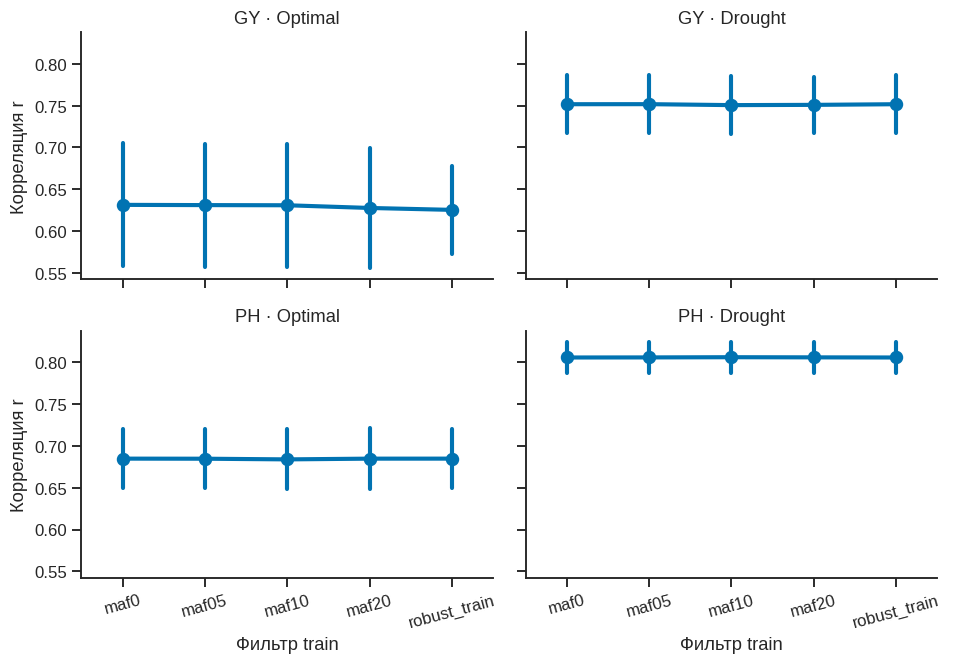

In [144]:
# T11/T10
from IPython.display import Image
display(Image(filename=str(OUT/'figures/G_filters.png')))

In [159]:
# maize07_explained_v2: filters_interpretation
# T11: фильтруется train; test и пороги не подбираются задним числом.
G_latest=pd.DataFrame(metrics_rows).query("stage == 'G' and model == 'GBLUP'")
G_review=G_latest.groupby(['trait','condition','scenario']).agg(r_mean=('r','mean'),rmse_mean=('rmse','mean'),markers_mean=('n_markers','mean'),removed_mean=('train_removed','mean')).reset_index()
display(G_review.round(3))
robust_rows=G_review.query("scenario == 'robust_train'")
explain_result('Что проверяют фильтры — T11',[
    'F проверяет отбор линий по близости и по размеру train. G отдельно проверяет маркерные пороги и robust-фильтрацию обучающего фенотипа. Это разные операции, их нельзя объединять под словом «очистка» без уточнения.',
    'Для кода 0/1 порог 0,05/0,10/0,20 относится к частоте более редкого бинарного состояния, рассчитанной в train; это не автоматически частота аллеля диплоидного SNP. Также удаляются константные в train маркеры.',
    'В таблице показаны реальное среднее число оставшихся маркеров и удалённых train-строк. Если r/RMSE почти не меняются, нельзя объявлять фильтр полезным только потому, что он удалил больше данных.',
    'Robust-правило: |0,67448975×(y−median)/MAD|>4,5. При MAD=0 фильтр пропускается. Удаление действует только на train; проверочный набор остаётся тем же, что в A для 2020. Отдельного удаления больших ошибок или экстремумов test нет.',
    'Выводы о фильтрах и размерах относятся к представленным опытам с target=2020. Лучший порог, выбранный после просмотра test, потребовал бы нового независимого подтверждения; здесь это анализ чувствительности, не оптимизированный финальный pipeline.'
])

,trait,condition,scenario,r_mean,rmse_mean,markers_mean,removed_mean
0,GY,Drought,maf0,0.752,0.614,4610.5,0.0
1,GY,Drought,maf05,0.752,0.614,4538.2,0.0
2,GY,Drought,maf10,0.751,0.615,4098.4,0.0
3,GY,Drought,maf20,0.751,0.615,2777.9,0.0
4,GY,Drought,robust_train,0.752,0.614,4610.5,0.0
5,GY,Optimal,maf0,0.631,1.260,4610.5,0.0
6,GY,Optimal,maf05,0.631,1.261,4538.2,0.0
7,GY,Optimal,maf10,0.631,1.261,4098.4,0.0
8,GY,Optimal,maf20,0.628,1.264,2777.9,0.0
9,GY,Optimal,robust_train,0.625,1.272,4610.5,7.6


### Что проверяют фильтры — T11

F проверяет отбор линий по близости и по размеру train. G отдельно проверяет маркерные пороги и robust-фильтрацию обучающего фенотипа. Это разные операции, их нельзя объединять под словом «очистка» без уточнения.

Для кода 0/1 порог 0,05/0,10/0,20 относится к частоте более редкого бинарного состояния, рассчитанной в train; это не автоматически частота аллеля диплоидного SNP. Также удаляются константные в train маркеры.

В таблице показаны реальное среднее число оставшихся маркеров и удалённых train-строк. Если r/RMSE почти не меняются, нельзя объявлять фильтр полезным только потому, что он удалил больше данных.

Robust-правило: |0,67448975×(y−median)/MAD|>4,5. При MAD=0 фильтр пропускается. Удаление действует только на train; проверочный набор остаётся тем же, что в A для 2020. Отдельного удаления больших ошибок или экстремумов test нет.

Выводы о фильтрах и размерах относятся к представленным опытам с target=2020. Лучший порог, выбранный после просмотра test, потребовал бы нового независимого подтверждения; здесь это анализ чувствительности, не оптимизированный финальный pipeline.

In [162]:
# maize07_explained_v2: G_specific_findings
# T11: удаление наблюдений не является улучшением само по себе.
g_examples=G_review.set_index(['trait','condition','scenario'])
g_base=g_examples.loc[('GY','Optimal','maf0')]
g_robust=g_examples.loc[('GY','Optimal','robust_train')]
g_high=g_examples.loc[('GY','Optimal','maf20')]
explain_result('Конкретный результат фильтрации — T11',[
    f"Для GY Optimal 2020 robust-фильтр удалял в среднем {g_robust.removed_mean:.1f} train-записи на разбиение. Средняя r изменилась с {g_base.r_mean:.3f} до {g_robust.r_mean:.3f}, RMSE — с {g_base.rmse_mean:.3f} до {g_robust.rmse_mean:.3f} т/га. Это не улучшение по данным метрикам; необычные значения не обязательно являются ошибками.",
    f"Порог 0,20 оставлял в среднем {g_high.markers_mean:.0f} маркеров вместо {g_base.markers_mean:.0f}, при r={g_high.r_mean:.3f} против {g_base.r_mean:.3f}. В данном опыте сильное сокращение панели не дало выигрыша. Это описательное сравнение зафиксированных порогов, не утверждение о значимом ухудшении."
])

### Конкретный результат фильтрации — T11

Для GY Optimal 2020 robust-фильтр удалял в среднем 7.6 train-записи на разбиение. Средняя r изменилась с 0.631 до 0.625, RMSE — с 1.260 до 1.272 т/га. Это не улучшение по данным метрикам; необычные значения не обязательно являются ошибками.

Порог 0,20 оставлял в среднем 2778 маркеров вместо 4610, при r=0.628 против 0.631. В данном опыте сильное сокращение панели не дало выигрыша. Это описательное сравнение зафиксированных порогов, не утверждение о значимом ухудшении.

## 4. MCMC: что именно диагностируем

Для первого разбиения 2018 Optimal берём сохранённую цепь seed=1 из A и заново запускаем ещё две цепи (101 и 201). Порог: rank-normalized Rhat<1,01 и bulk ESS≥400. Проверяем **только сохранённые скаляры**: среднее и дисперсии. Хорошие значения не доказывают сходимость всех 4612 эффектов маркеров. Это выбранный диагностический пример, а не проверка каждого разбиения.

In [132]:
# T02/T10
started=time.perf_counter()
diagnostic_rows=[]
trace_tables=[]
for trait,model in product(TRAITS,['BRR','BayesA']):
    data=records(2018,trait,'Optimal')
    tr,te=next(random_splits(len(data),train_frac=CONFIG['train_fraction'],n_reps=1,seed=1))
    train=data.iloc[tr]
    A=X[train.row]
    A=A[:,A.var(axis=0)>0]
    for seed in [101,201]:
        if model=='BRR': fit=brr_fit(train.y.to_numpy(),A,seed=seed,**CONFIG['gibbs'])
        else: fit=bayesa_fit(train.y.to_numpy(),A,seed=seed,**CONFIG['gibbs'])
        trace_store[(trait,model,seed)]=fit['trace'].copy()
    names=['mu','sigma2_b','sigma2_e'] if model=='BRR' else ['mu','sigma2_e']
    chains=np.stack([trace_store[(trait,model,seed)] for seed in [1,101,201]])
    assert chains.shape[:2]==(3,1200) and np.isfinite(chains).all()
    posterior={name:chains[:,:,j] for j,name in enumerate(names)}
    idata=az.from_dict(posterior=posterior)
    rhat,ess=az.rhat(idata),az.ess(idata,method='bulk')
    for name in names:
        rh,es=float(rhat[name].values),float(ess[name].values)
        diagnostic_rows.append(dict(trait=trait,model=model,parameter=name,rhat=rh,ess_bulk=es,pass_thresholds=bool(rh<1.01 and es>=400)))
    for k,seed in enumerate([1,101,201]):
        frame=pd.DataFrame(chains[k],columns=names)
        frame['draw']=np.arange(1200)*CONFIG['gibbs']['thin']+CONFIG['gibbs']['burn_in']
        frame['trait'],frame['model'],frame['seed']=trait,model,seed
        trace_tables.append(frame)
diagnostics=pd.DataFrame(diagnostic_rows)
diagnostics.to_csv(OUT/'mcmc_diagnostics.csv',index=False)
trace_table=pd.concat(trace_tables,ignore_index=True)
trace_table.to_csv(OUT/'mcmc_scalar_traces.csv',index=False)
display(diagnostics.round(4))
fig,axes=plt.subplots(2,2,figsize=(11,6))
for ax,(trait,model) in zip(axes.flat,product(TRAITS,['BRR','BayesA'])):
    d=trace_table.query('trait == @trait and model == @model')
    for seed,color in zip([1,101,201],sns.color_palette('colorblind',3)):
        c=d.query('seed == @seed')
        ax.plot(c.draw,c.sigma2_e,label=str(seed),lw=.55,alpha=.8,color=color)
    ax.set(title=f'{trait} · {model}',xlabel='Шаг MCMC',ylabel='Остаточная дисперсия')
    ax.legend(title='Seed')
fig.tight_layout()
for ext in ['png','svg']: fig.savefig(OUT/f'figures/MCMC_traces.{ext}',bbox_inches='tight')
plt.show()
active_seconds+=time.perf_counter()-started
pd.DataFrame(stage_times+[dict(part='MCMC',seconds=time.perf_counter()-started,active_seconds=active_seconds)]).to_csv(OUT/'stage_times_with_diagnostics.csv',index=False)
print(f'Порог прошли {diagnostics.pass_thresholds.sum()} из {len(diagnostics)} скаляров; ограничения диагностики остаются.')

,trait,model,parameter,rhat,ess_bulk,pass_thresholds
0,GY,BRR,mu,0.9997,3607.9919,True
1,GY,BRR,sigma2_b,1.0096,213.1014,False
2,GY,BRR,sigma2_e,1.0020,816.9432,True
3,GY,BayesA,mu,0.9997,3632.4931,True
4,GY,BayesA,sigma2_e,1.0004,2229.2132,True
5,PH,BRR,mu,0.9997,3598.1733,True
6,PH,BRR,sigma2_b,1.0076,251.6923,False
7,PH,BRR,sigma2_e,1.0062,892.8027,True
8,PH,BayesA,mu,0.9997,3639.5312,True
9,PH,BayesA,sigma2_e,1.0009,1683.0701,True


Порог прошли 8 из 10 скаляров; ограничения диагностики остаются.


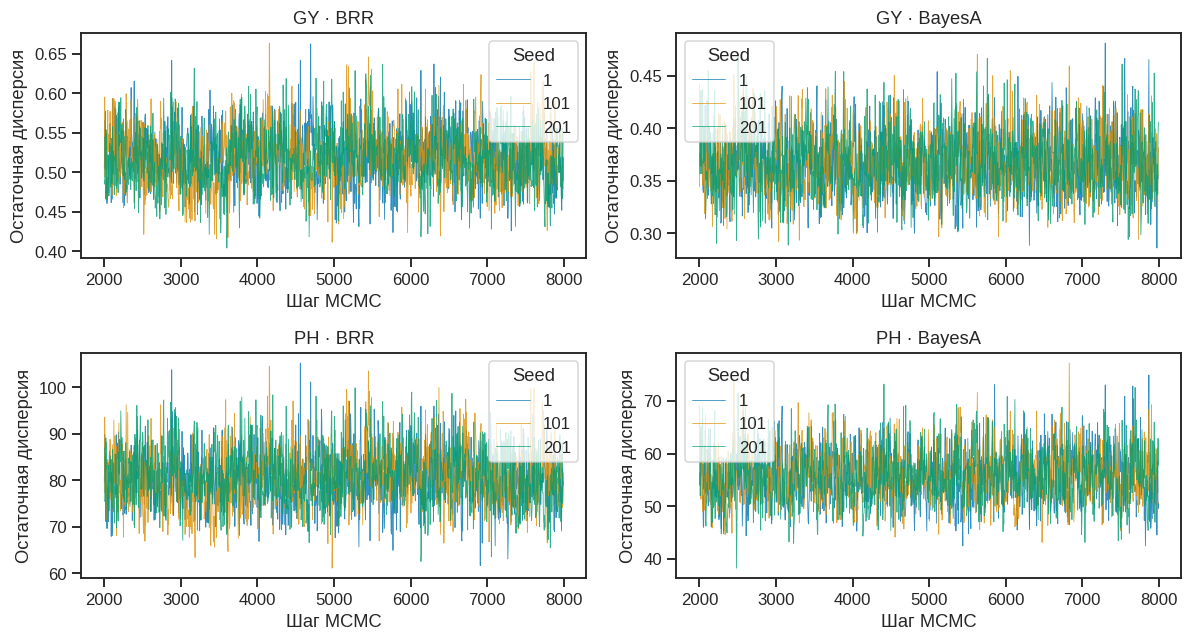

In [145]:
# T02/T10
from IPython.display import Image
display(Image(filename=str(OUT/'figures/MCMC_traces.png')))

In [160]:
# maize07_explained_v2: MCMC_interpretation
# Дополнительная проверка надёжности T02, не диагностика всех эффектов маркеров.
failed_diagnostics=diagnostics.loc[~diagnostics.pass_thresholds.astype(bool)]
explain_result('Что ограничивает выводы BRR/BayesA',[
    f"Из {len(diagnostics)} сохранённых скаляров оба порога прошли {len(diagnostics)-len(failed_diagnostics)}. Не прошли: "+'; '.join(f"{r.trait}/{r.model}/{r.parameter}: Rhat={r.rhat:.4f}, ESS={r.ess_bulk:.0f}" for r in failed_diagnostics.itertuples())+'.',
    'Недостаточный ESS означает, что зависимые сохранённые шаги несут меньше независимой информации, чем нужно по выбранному порогу. Для более уверенных выводов о дисперсиях BRR нужны более длинные цепи и повторная диагностика.',
    'Здесь не запускали дополнительные цепи задним числом и не исправляли неудачную диагностику текстом. Проверены среднее и дисперсии выбранного примера, но не все маркерные эффекты и не каждое разбиение.'
])

### Что ограничивает выводы BRR/BayesA

Из 10 сохранённых скаляров оба порога прошли 8. Не прошли: GY/BRR/sigma2_b: Rhat=1.0096, ESS=213; PH/BRR/sigma2_b: Rhat=1.0076, ESS=252.

Недостаточный ESS означает, что зависимые сохранённые шаги несут меньше независимой информации, чем нужно по выбранному порогу. Для более уверенных выводов о дисперсиях BRR нужны более длинные цепи и повторная диагностика.

Здесь не запускали дополнительные цепи задним числом и не исправляли неудачную диагностику текстом. Проверены среднее и дисперсии выбранного примера, но не все маркерные эффекты и не каждое разбиение.

## 5. Отдельный пример: RR-BLUP/GBLUP и BayesA, 2017–2019 → 2020

Повторяем самостоятельное межгодовое сравнение для GY Optimal. Фиксированные эффекты обучающих лет одинаковы; среднее 2020 не используется. RR-BLUP получает λ, согласованную с масштабом GBLUP, и должен дать тот же прогноз. BayesA обучается со своими маркерными дисперсиями. Не стоит ожидать, что более сложный приор сам устранит межгодовой сдвиг.

In [133]:
# T02/T10
started=time.perf_counter()
train=records([2017,2018,2019],'GY','Optimal')
target=records(2020,'GY','Optimal')
F,T,names=fixed_design(train,target)
prepared,_=prepare_kernel('GBLUP',train,target,F)
y=train.y.to_numpy(float)
fit_g=gblup_fit_reml(y,prepared['K'],F=F,eigen=prepared['eigen'],bounds=tuple(CONFIG['reml_log_lambda_bounds']))
pred_g=gblup_predict(fit_g,prepared['cross'],T)
keep=prepared['outer_keep']
A,B=X[train.row][:,keep],X[target.row][:,keep]
mean=A.mean(axis=0)
fit_rr=rrblup_fit(y,A-mean,fit_g['vc']['lam']*prepared['scale'],F)
pred_rr=predict_gebv(fit_rr,B-mean,T)
np.testing.assert_allclose(pred_rr,pred_g,atol=1e-6)
fit_ba=bayesa_fit(y,A,F=F,seed=1,**CONFIG['gibbs'])
pred_ba=T@fit_ba['beta_fixed']+(B-mean)@fit_ba['beta']
example_predictions=target[['GID','Year','Condition','y']].rename(columns={'y':'observed'}).copy()
example_metrics=[]
for model,pred in [('GBLUP',pred_g),('RR-BLUP',pred_rr),('BayesA',pred_ba)]:
    example_predictions[model]=pred
    example_metrics.append(dict(model=model,**regression_metrics(target.y.to_numpy(),pred)))
example_predictions.to_csv(OUT/'interyear_example_predictions.csv',index=False)
example_metrics=pd.DataFrame(example_metrics)
example_metrics.to_csv(OUT/'interyear_example_metrics.csv',index=False)
display(example_metrics.round(4))
print('max |RR−GBLUP| =',float(np.max(np.abs(pred_rr-pred_g))))
active_seconds+=time.perf_counter()-started

,model,r,rmse,mae,r2
0,GBLUP,0.1281,1.9368,1.2590,-0.3344
1,RR-BLUP,0.1281,1.9368,1.2590,-0.3344
2,BayesA,0.0630,2.0485,1.3388,-0.4928


max |RR−GBLUP| = 9.592326932761353e-14


## 6. Независимая проверка сохранённых результатов

Здесь читаются **только файлы, созданные предыдущими ячейками в новом `RUN_ID`**. По самим новым прогнозам заново считаем четыре метрики явными формулами (не вызывая функцию метрик модели). Проверяем соответствие каждой строки наблюдения её GID и отсутствие пересечения train/test во всех сохранённых разбиениях. Проверочные наборы E/F/G дополнительно сверяем между вариантами. Это проверка результата текущего Run All, не использование готового результата вместо обучения.

In [134]:
# T02/T10
started=time.perf_counter()
M=pd.DataFrame(metrics_rows)
assert len(M)==6412 and (M.status=='ok').all()
keys=['case_id','stage','trait','condition','year','repeat','scenario','resample','model']
assert not M.duplicated(keys).any()
# case_id identifies training/target rows; scenario is also needed to distinguish
# deliberately identical 'all' predictions labelled under three F strategies.
checks=[]
prediction_row_count=0
for path in sorted(OUT.glob('predictions_*.parquet')):
    p=pd.read_parquet(path,columns=keys+['GID','row','observed','predicted'])
    prediction_row_count+=len(p)
    for (trait,condition),d in p.groupby(['trait','condition']):
        row=d['row'].to_numpy(int)
        np.testing.assert_array_equal(pheno.GID.to_numpy()[row],d.GID.to_numpy())
        np.testing.assert_allclose(pheno[f'{trait}_{condition}'].to_numpy()[row],d.observed.to_numpy(),atol=0,rtol=0)
    for identity,d in p.groupby(keys,sort=False,dropna=False):
        y=d.observed.to_numpy(float); pred=d.predicted.to_numpy(float)
        error=y-pred
        yc,pc=y-y.mean(),pred-pred.mean()
        tol=1e-12*max(1.,np.abs(y).max(),np.abs(pred).max())
        r=float(np.dot(yc,pc)/np.sqrt(np.dot(yc,yc)*np.dot(pc,pc))) if min(y.std(),pred.std())>tol else np.nan
        manual=dict(r=r,rmse=float(np.sqrt(np.dot(error,error)/len(y))),mae=float(np.abs(error).sum()/len(y)),r2=float(1-np.dot(error,error)/np.dot(yc,yc)))
        checks.append(dict(zip(keys,identity),**manual))
    del p
manual=pd.DataFrame(checks)
audit=M.merge(manual,on=keys,validate='one_to_one',suffixes=('_saved','_manual'))
assert len(audit)==len(M)
errors={}
for metric in ['r','rmse','mae','r2']:
    np.testing.assert_allclose(audit[f'{metric}_saved'],audit[f'{metric}_manual'],atol=1e-10,rtol=1e-10,equal_nan=True)
    errors[metric]=float(np.nanmax(np.abs(audit[f'{metric}_saved']-audit[f'{metric}_manual'])))
M['fit_id']=M.case_id.str.rsplit('_',n=1).str[0]
M.to_csv(OUT/'metrics_per_split.csv',index=False)
print('Новых строк прогнозов:',f'{prediction_row_count:,}')
print('Метрики независимо совпали во всех',len(audit),'оценках; максимальные отклонения:',errors)

Новых строк прогнозов: 2,920,292
Метрики независимо совпали во всех 6412 оценках; максимальные отклонения: {'r': 1.2212453270876722e-15, 'rmse': 1.4210854715202004e-14, 'mae': 0.0, 'r2': 2.1316282072803006e-14}


In [135]:
# T02/T10
manifest_count=0
A_test_sets,E_test_sets,F_test_sets,G_test_sets={}, {}, {}, {}
BD_sets={}
case_count=0
manifest_keys=[k for k in keys if k!='model']
for path in sorted(OUT.glob('manifest_*.parquet')):
    d=pd.read_parquet(path,columns=manifest_keys+['GID','role'])
    manifest_count+=len(d)
    for identity,group in d.groupby(manifest_keys,sort=False,dropna=False):
        meta=dict(zip(manifest_keys,identity))
        train_ids=set(group.loc[group.role=='train','GID'])
        test_ids=set(group.loc[group.role=='test','GID'])
        assert train_ids and test_ids and not train_ids&test_ids
        case_count+=1
        basic=(meta['trait'],meta['condition'],meta['repeat'])
        if meta['stage']=='A' and meta['year']==2020:
            A_test_sets[basic]=test_ids
        elif meta['stage']=='E':
            key=meta['repeat']
            if key in E_test_sets: assert E_test_sets[key]==test_ids
            E_test_sets[key]=test_ids
        elif meta['stage']=='F':
            if basic in F_test_sets: assert F_test_sets[basic]==test_ids
            F_test_sets[basic]=test_ids
        elif meta['stage']=='G':
            if basic in G_test_sets: assert G_test_sets[basic]==test_ids
            G_test_sets[basic]=test_ids
        elif meta['stage'] in ['B','D']:
            key=(meta['year'],)+basic
            BD_sets.setdefault(key,{})[meta['scenario']]=(train_ids,test_ids)
    del d
assert len(A_test_sets)==len(G_test_sets)==40
assert A_test_sets==G_test_sets
assert len(E_test_sets)==10 and len(F_test_sets)==40
assert len(BD_sets)==160
for triple in BD_sets.values():
    assert set(triple)=={'opposite','single','pooled'}
    assert triple['opposite']==triple['single']==triple['pooled']
print('Проверено разбиений/оценочных подвыборок:',case_count)
print('Строк манифеста:',f'{manifest_count:,}','; нет пересечений GID train/test.')
print('E: одинаковые 413 test; F: одинаковые 85% target; G: test совпадает с A; B/D: 160 согласованных троек.')
active_seconds+=time.perf_counter()-started
unique_fits=M.drop_duplicates(['fit_id','model'])
completion=dict(run_id=RUN_ID,completed=True,metric_rows=len(M),prediction_rows=prediction_row_count,manifest_rows=manifest_count,evaluation_cases=case_count,
                actual_fit_calls=len(unique_fits),genomic_fit_calls=int((unique_fits.model!='Baseline').sum()),
                preparation_seconds=float(unique_fits.preparation_seconds.sum()),fit_seconds=float(unique_fits.fit_seconds.sum()),predict_seconds=float(unique_fits.predict_seconds.sum()),
                active_seconds=active_seconds,elapsed_seconds=time.perf_counter()-run_clock,
                metric_max_errors=errors,matched_BD_triples=160,mcmc_scalars_passing=int(diagnostics.pass_thresholds.sum()),mcmc_scalars_checked=len(diagnostics),
                separate_example_metrics=len(example_metrics),mcmc_scope='saved scalar parameters only',prior_results_used=False)
(OUT/'completion_audit.json').write_text(json.dumps(completion,indent=2))
display(pd.Series(completion))

Проверено разбиений/оценочных подвыборок: 2244
Строк манифеста: 3,498,974 ; нет пересечений GID train/test.
E: одинаковые 413 test; F: одинаковые 85% target; G: test совпадает с A; B/D: 160 согласованных троек.


run_id                                              20261026T053004Z_4b1b13e7
completed                                                                True
metric_rows                                                              6412
prediction_rows                                                       2920292
manifest_rows                                                         3498974
evaluation_cases                                                         2244
actual_fit_calls                                                         3684
genomic_fit_calls                                                        2484
preparation_seconds                                                662.510034
fit_seconds                                                       4158.368514
predict_seconds                                                      7.812135
active_seconds                                                    5065.868764
elapsed_seconds                                                 

## 7. Итоги и практический смысл

Ниже сохранена численная сводка полного обучающего прогона, затем — расширенный итог v2.
При новом Run All числа берутся из нового расчёта. Все сравнения исследовательские:
отдельной вложенной настройки всех гиперпараметров и дополнительной внешней проверки выбранных лучших настроек здесь нет.

In [136]:
# T02/T05/T10
text=[]
for trait in TRAITS:
    d=A_metrics.query("trait == @trait and model != 'Baseline'")
    means=d.groupby('model').r.mean().sort_values(ascending=False)
    text.append(f"- **Внутри группы, {trait}:** наибольшая средняя r у {means.index[0]} ({means.iloc[0]:.3f}); у GBLUP {means['GBLUP']:.3f}. Это среднее по восьми группам и десяти разбиениям, не независимый тест превосходства.")
transfer=C_full.query("year == 2020 and scenario == 'LOYO' and trait == 'GY' and condition == 'Optimal' and model == 'GBLUP'").iloc[0]
text.append(f"- **Перенос на 2020 без локальных линий:** GY Optimal, GBLUP: r={transfer.r:.3f}, RMSE={transfer.rmse:.3f} т/га, R²={transfer.r2:.3f}. Обычное случайное разбиение не отражает эту трудность переноса.")
local=E.query("source == '2017+2018+2019' and model == 'GBLUP'").groupby('local_n')[['r','rmse','r2']].mean()
text.append(f"- **Локальные линии:** для источника 2017+2018+2019 средняя r меняется с {local.loc[0,'r']:.3f} до {local.loc[73,'r']:.3f}, RMSE — с {local.loc[0,'rmse']:.3f} до {local.loc[73,'rmse']:.3f} т/га при добавлении 73 линий. Часть выигрыша связана с возможностью оценить уровень целевого года, поэтому сравнивайте также baseline.")
pooled=deltas.reset_index().query("model == 'GBLUP'").groupby(['trait','condition']).r_pooled_minus_single.mean()
text.append('- **Объединение режимов:** средняя Δr pooled−single у GBLUP: '+', '.join(f'{t}/{c}: {v:+.3f}' for (t,c),v in pooled.items())+'. Общий генетический эффект не гарантирует улучшения; здесь требуется учитывать неодинаковые реакции на режим.')
failed=diagnostics.loc[~diagnostics.pass_thresholds]
text.append(f"- **MCMC:** оба порога прошли {len(diagnostics)-len(failed)}/{len(diagnostics)} сохранённых скаляров. "+('Не прошли: '+', '.join(f"{r.trait} {r.model} {r.parameter} (Rhat={r.rhat:.4f}, ESS={r.ess_bulk:.0f})" for r in failed.itertuples())+'. Выводы BRR требуют осторожности; длина цепей не увеличивалась задним числом.' if len(failed) else 'Это не диагностика всех эффектов маркеров.'))
text.append(f"- **RR-BLUP = GBLUP:** в межгодовом примере max |разность прогнозов|={np.max(np.abs(pred_rr-pred_g)):.2g}; считать их независимыми конкурентами нельзя.")
text.append('- **Ограничения:** нет семейных меток для family-wise CV; сдвиги года, генетической когорты и площадок нельзя разделить этими CSV. В F выбор использует генотипы всей target-панели. SD разных разделов имеют разные источники. Высокая r не равна положительному предиктивному R² и не доказывает точность истинной племенной ценности.')
display(Markdown('\n\n'.join(text)))

- **Внутри группы, GY:** наибольшая средняя r у KBLUP (0.654); у GBLUP 0.645. Это среднее по восьми группам и десяти разбиениям, не независимый тест превосходства.

- **Внутри группы, PH:** наибольшая средняя r у KBLUP (0.737); у GBLUP 0.730. Это среднее по восьми группам и десяти разбиениям, не независимый тест превосходства.

- **Перенос на 2020 без локальных линий:** GY Optimal, GBLUP: r=0.128, RMSE=1.937 т/га, R²=-0.334. Обычное случайное разбиение не отражает эту трудность переноса.

- **Локальные линии:** для источника 2017+2018+2019 средняя r меняется с 0.127 до 0.483, RMSE — с 1.942 до 1.481 т/га при добавлении 73 линий. Часть выигрыша связана с возможностью оценить уровень целевого года, поэтому сравнивайте также baseline.

- **Объединение режимов:** средняя Δr pooled−single у GBLUP: GY/Drought: -0.206, GY/Optimal: -0.098, PH/Drought: -0.060, PH/Optimal: -0.150. Общий генетический эффект не гарантирует улучшения; здесь требуется учитывать неодинаковые реакции на режим.

- **MCMC:** оба порога прошли 8/10 сохранённых скаляров. Не прошли: GY BRR sigma2_b (Rhat=1.0096, ESS=213), PH BRR sigma2_b (Rhat=1.0076, ESS=252). Выводы BRR требуют осторожности; длина цепей не увеличивалась задним числом.

- **RR-BLUP = GBLUP:** в межгодовом примере max |разность прогнозов|=9.6e-14; считать их независимыми конкурентами нельзя.

- **Ограничения:** нет семейных меток для family-wise CV; сдвиги года, генетической когорты и площадок нельзя разделить этими CSV. В F выбор использует генотипы всей target-панели. SD разных разделов имеют разные источники. Высокая r не равна положительному предиктивному R² и не доказывает точность истинной племенной ценности.

In [164]:
# maize07_explained_v2: revision_summary
# Все тезисы с числами берутся из выполненных выше сводок.
explain_result('Итог: что можно утверждать по этому ноутбуку',[
    'Построены распределения, описана генетическая структура, пять геномных методов сопоставлены для обоих признаков внутри групп. Три сценария режимов сравниваются на согласованных GID для GBLUP/KBLUP и baseline. Близость и размер обучения, а также train-фильтры проверены в опытах с target=2020.',
    'Внешний перенос года существенно сложнее обычного случайного split. Небольшой набор фенотипированных линий целевого года помогает, но его польза сочетает информацию о генетической когорте и уровне целевого года. Больше исторических строк или больше фильтрации не гарантируют лучшего прогноза.',
    'Границы покрытия остаются видимыми: не все пять методов испытаны во всех сценариях; повторные подвыборки фиксированного target не являются повторным обучением; опыт E ограничен GY Optimal; GSSI/KSSI не воспроизведены; два скаляра BRR не прошли ESS-порог.',
    'Поэтому ответ «всё ТЗ сделано без оговорок» был бы слишком сильным. В начале дана карта того, какие конкретно пункты выполнены и в каком объёме. Расширение до всех методов во всех сценариях или десяти изменяемых train для C/F потребовало бы отдельного вычислительного эксперимента.',
    'В этой поясняющей версии сохранено обучение проверенного полного прогона. Заново выполнены изменённые графики и новые сводки; ещё один полный обучающий Run All не запускался. При вашем новом Run All обучение остаётся в ячейках и выполняется с нуля.'
])

### Итог: что можно утверждать по этому ноутбуку

Построены распределения, описана генетическая структура, пять геномных методов сопоставлены для обоих признаков внутри групп. Три сценария режимов сравниваются на согласованных GID для GBLUP/KBLUP и baseline. Близость и размер обучения, а также train-фильтры проверены в опытах с target=2020.

Внешний перенос года существенно сложнее обычного случайного split. Небольшой набор фенотипированных линий целевого года помогает, но его польза сочетает информацию о генетической когорте и уровне целевого года. Больше исторических строк или больше фильтрации не гарантируют лучшего прогноза.

Границы покрытия остаются видимыми: не все пять методов испытаны во всех сценариях; повторные подвыборки фиксированного target не являются повторным обучением; опыт E ограничен GY Optimal; GSSI/KSSI не воспроизведены; два скаляра BRR не прошли ESS-порог.

Поэтому ответ «всё ТЗ сделано без оговорок» был бы слишком сильным. В начале дана карта того, какие конкретно пункты выполнены и в каком объёме. Расширение до всех методов во всех сценариях или десяти изменяемых train для C/F потребовало бы отдельного вычислительного эксперимента.

В этой поясняющей версии сохранено обучение проверенного полного прогона. Заново выполнены изменённые графики и новые сводки; ещё один полный обучающий Run All не запускался. При вашем новом Run All обучение остаётся в ячейках и выполняется с нуля.

## Повторный запуск и комплект v2

1. Распакуйте `maize07_explained_v2.zip` в **новую папку**; сохраните прежнюю версию отдельно.
2. Установите зависимости из `requirements.txt` (`uv pip install -r requirements.txt`).
3. Откройте `07_maize_years_envs_explained_v2.ipynb` из корня проекта или его `notebooks/`, выберите окружение.
4. Читайте сохранённые outputs без запуска либо выполняйте ячейки сверху вниз / **Run All**.
   Run All **обучает с нуля**, создавая отдельную папку результатов; готовая `results/` ему не нужна.
   Параметры находятся в CONFIG. Полный расчёт исходной версии занял около 91 минуты в использованном окружении; это не гарантия времени на другой машине.

Десять файлов `gp_models` и два исходных CSV не менялись в v2. Никаких additions/readable/experiment_runner нет:
управление экспериментами остаётся в ячейках. Реализации моделей — в соответствующих модулях, лес использует scikit-learn.

В комплекте сохранены результаты полного прогона и добавлены таблицы BV, фактической IBS и сравнения со статьёй, а также новые PNG/SVG.
`revision_audit.json` описывает именно редакцию постобработки; он **не** заменяет `completion_audit.json` полного обучающего прогона.
Счётчики In[] отражают два этапа выполнения; номера карты — порядковые позиции ячеек, не эти счётчики.

При прерывании не считайте частичный запуск полным. Завершённые части имеют checkpoint-файлы с хешами.
Восстановление автоматически не включено: повторный Run All считает всё заново.